In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv("data/raw/medical_ecommerce_orders.csv")

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nBasic statistics:")
print(df.describe())


First 5 rows:
   order_id  order_date  customer_id  customer_age gender        city  \
0     10001  2025-01-01         1103            57   Male       Salem   
1     10002  2025-01-02         1180            66   Male    Tiruppur   
2     10003  2025-01-03         1093            61   Male  Coimbatore   
3     10004  2025-01-04         1015            36   Male  Coimbatore   
4     10005  2025-01-05         1107            59   Male     Chennai   

  product_id  quantity  discount payment_method  inventory_before  \
0       P002         9        15            UPI               194   
1       P004         4        15    Credit Card               104   
2       P003         6        10            UPI               149   
3       P007         7         5            UPI               115   
4       P009         6         0     Debit Card               142   

  order_status            product_name       category  unit_price  \
0    Completed     Glucose Test Strips  Diabetes Care         

In [3]:
#Outlier Deduction

Q1 = df["total_amount"].quantile(0.25)
Q3 = df["total_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\nTotal Amount Outlier Analysis")
print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

outliers = df[
    (df["total_amount"] < lower_bound)
    | (df["total_amount"] > upper_bound)
]

print(f"Number of total_amount outliers: {len(outliers)}")


Total Amount Outlier Analysis
Q1: 855.0
Q3: 3641.25
IQR: 2786.25
Lower Bound: -3324.375
Upper Bound: 7820.625
Number of total_amount outliers: 73


In [14]:
# 9. CHECK CATEGORICAL VALUES

categorical_columns = [
    "gender",
    "city",
    "payment_method",
    "order_status",
    "category"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())

print("\nOrder Status Distribution:")
print(df["order_status"].value_counts())

print("\nPayment Method Distribution:")
print(df["payment_method"].value_counts())

print("\nCity Distribution:")
print(df["city"].value_counts())

print("\nCategory Distribution:")
print(df["category"].value_counts())

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["day"] = df["order_date"].dt.day
df["day_of_week"] = df["order_date"].dt.dayofweek

df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

df["gross_amount"] = (
    df["unit_price"] * df["quantity"]
)

df["discount_amount"] = (
    df["gross_amount"] * df["discount"] / 100
)

df["calculated_total"] = (
    df["gross_amount"] - df["discount_amount"]
)


df["is_high_value_order"] = (
    df["total_amount"] > upper_bound
).astype(int)

df["amount_difference"] = (
    df["total_amount"] - df["calculated_total"]
)

print("\nMaximum amount calculation difference:")
print(df["amount_difference"].abs().max())

print("\nHigh-value order distribution:")
print(df["is_high_value_order"].value_counts())
output_file = "data/processed/cleaned_medical_orders.csv"

df.to_csv(output_file, index=False)

print("\nProcessed dataset saved successfully!")
print(f"Saved to: {output_file}")

print("\nSample total_amount outliers:")

print(
    outliers[
        [
            "order_id",
            "product_name",
            "category",
            "quantity",
            "discount",
            "unit_price",
            "total_amount",
            "order_status"
        ]
    ].sort_values(
        "total_amount",
        ascending=False
    ).head(20)
)

print(f"Number of total_amount outliers: {len(outliers)}")


Unique values in gender:
['Male' 'Female']

Unique values in city:
['Salem' 'Tiruppur' 'Coimbatore' 'Chennai' 'Trichy' 'Madurai']

Unique values in payment_method:
['UPI' 'Credit Card' 'Debit Card' 'COD']

Unique values in order_status:
['Completed' 'Cancelled' 'Returned']

Unique values in category:
['Diabetes Care' 'Diagnostics' 'Personal Care' 'Pain Relief' 'Supplements'
 'First Aid']

Order Status Distribution:
order_status
Completed    855
Cancelled    107
Returned      38
Name: count, dtype: int64

Payment Method Distribution:
payment_method
Credit Card    262
COD            261
UPI            246
Debit Card     231
Name: count, dtype: int64

City Distribution:
city
Madurai       182
Salem         172
Chennai       172
Trichy        170
Tiruppur      157
Coimbatore    147
Name: count, dtype: int64

Category Distribution:
category
Diabetes Care    209
Supplements      207
Diagnostics      206
Personal Care    185
Pain Relief      101
First Aid         92
Name: count, dtype: int64

In [5]:
categorical_columns = [
    "gender",
    "city",
    "payment_method",
    "order_status",
    "category"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())


Unique values in gender:
['Male' 'Female']

Unique values in city:
['Salem' 'Tiruppur' 'Coimbatore' 'Chennai' 'Trichy' 'Madurai']

Unique values in payment_method:
['UPI' 'Credit Card' 'Debit Card' 'COD']

Unique values in order_status:
['Completed' 'Cancelled' 'Returned']

Unique values in category:
['Diabetes Care' 'Diagnostics' 'Personal Care' 'Pain Relief' 'Supplements'
 'First Aid']


In [6]:
print("\nOrder Status Distribution:")
print(df["order_status"].value_counts())

print("\nPayment Method Distribution:")
print(df["payment_method"].value_counts())

print("\nCity Distribution:")
print(df["city"].value_counts())

print("\nCategory Distribution:")
print(df["category"].value_counts())


Order Status Distribution:
order_status
Completed    855
Cancelled    107
Returned      38
Name: count, dtype: int64

Payment Method Distribution:
payment_method
Credit Card    262
COD            261
UPI            246
Debit Card     231
Name: count, dtype: int64

City Distribution:
city
Madurai       182
Salem         172
Chennai       172
Trichy        170
Tiruppur      157
Coimbatore    147
Name: count, dtype: int64

Category Distribution:
category
Diabetes Care    209
Supplements      207
Diagnostics      206
Personal Care    185
Pain Relief      101
First Aid         92
Name: count, dtype: int64


In [8]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["day"] = df["order_date"].dt.day
df["day_of_week"] = df["order_date"].dt.dayofweek

In [9]:

df["is_weekend"] = (
    df["day_of_week"].isin([5, 6])
).astype(int)

In [10]:
df["gross_amount"] = (
    df["unit_price"] * df["quantity"]
)

In [11]:
df["discount_amount"] = (
    df["gross_amount"] * df["discount"] / 100
)

In [12]:
df["calculated_total"] = (
    df["gross_amount"] - df["discount_amount"]
)

In [13]:
output_file = "data/processed/cleaned_medical_orders.csv"

df.to_csv(output_file, index=False)

print("\nProcessed dataset saved successfully!")
print(f"Saved to: {output_file}")


Processed dataset saved successfully!
Saved to: data/processed/cleaned_medical_orders.csv


Processed dataset loaded successfully!
Rows: 1000
Columns: 26

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_id             1000 non-null   int64  
 1   order_date           1000 non-null   object 
 2   customer_id          1000 non-null   int64  
 3   customer_age         1000 non-null   int64  
 4   gender               1000 non-null   object 
 5   city                 1000 non-null   object 
 6   product_id           1000 non-null   object 
 7   quantity             1000 non-null   int64  
 8   discount             1000 non-null   int64  
 9   payment_method       1000 non-null   object 
 10  inventory_before     1000 non-null   int64  
 11  order_status         1000 non-null   object 
 12  product_name         1000 non-null   object 
 13  category             1000 non-null   object 
 14  unit_

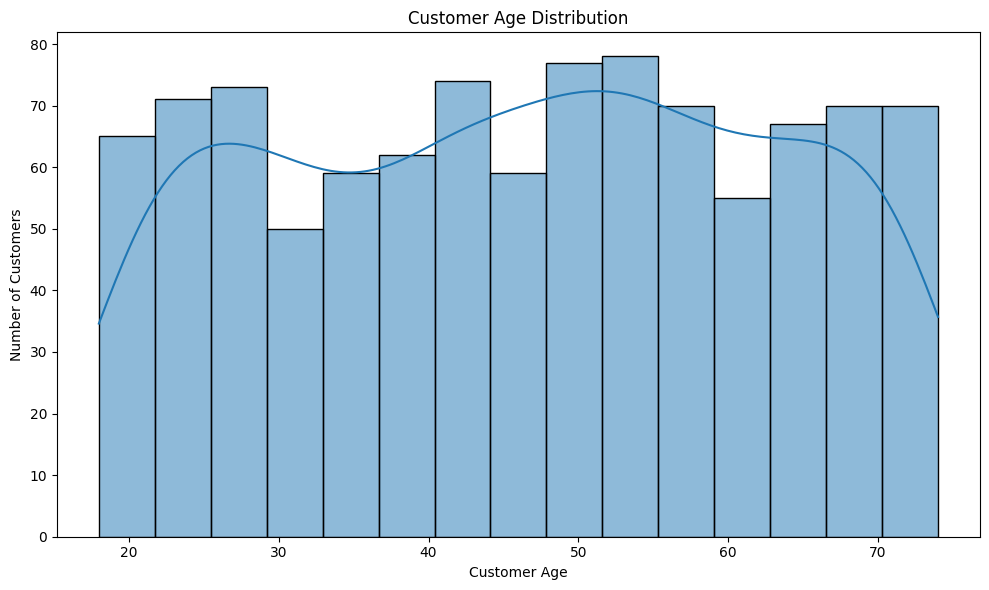

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#EDA
# ============================================================
# 1. LOAD PROCESSED DATASET
# ============================================================

df = pd.read_csv("data/processed/cleaned_medical_orders.csv")

print("Processed dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")


# ============================================================
# 2. BASIC INFORMATION
# ============================================================

print("\nDataset Information:")
print(df.info())

print("\nBasic Statistics:")
print(df.describe())


# ============================================================
# 3. CUSTOMER AGE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="customer_age",
    bins=15,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


Orders by Category:
category
Diabetes Care    209
Supplements      207
Diagnostics      206
Personal Care    185
Pain Relief      101
First Aid         92
Name: count, dtype: int64


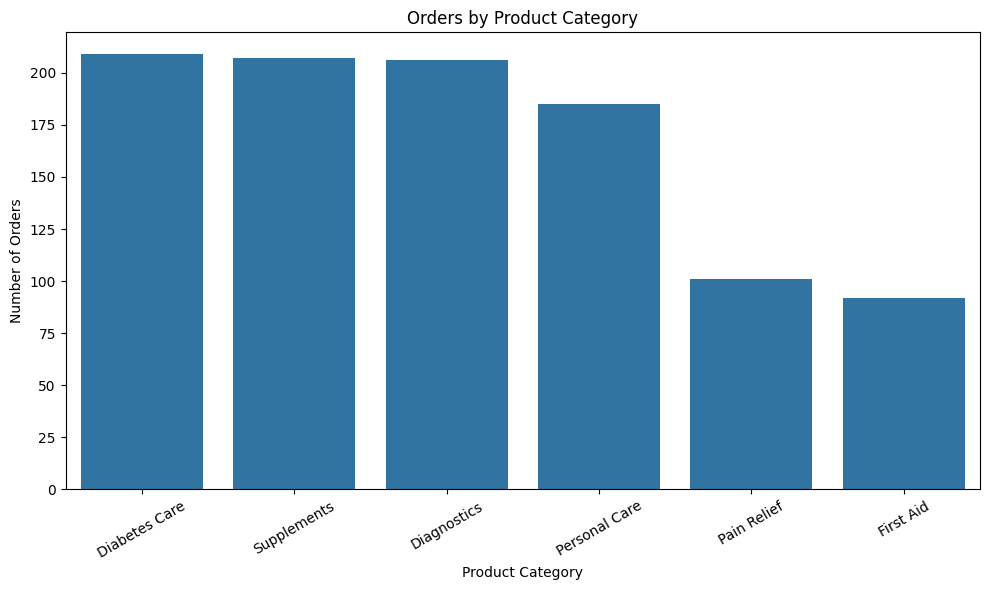

In [18]:

# ============================================================
# 4. ORDERS BY CATEGORY
# ============================================================

category_counts = df["category"].value_counts()

print("\nOrders by Category:")
print(category_counts)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()



Revenue by Product:
product_name
Blood Pressure Monitor    789390.0
Glucometer                583440.0
First Aid Kit             319837.5
Glucose Test Strips       290972.5
Vitamin D Tablets         205245.0
Calcium Tablets           150030.0
Digital Thermometer       147420.0
Pain Relief Gel           118350.0
Hand Sanitizer             74376.0
Surgical Mask              55752.0
Name: total_amount, dtype: float64


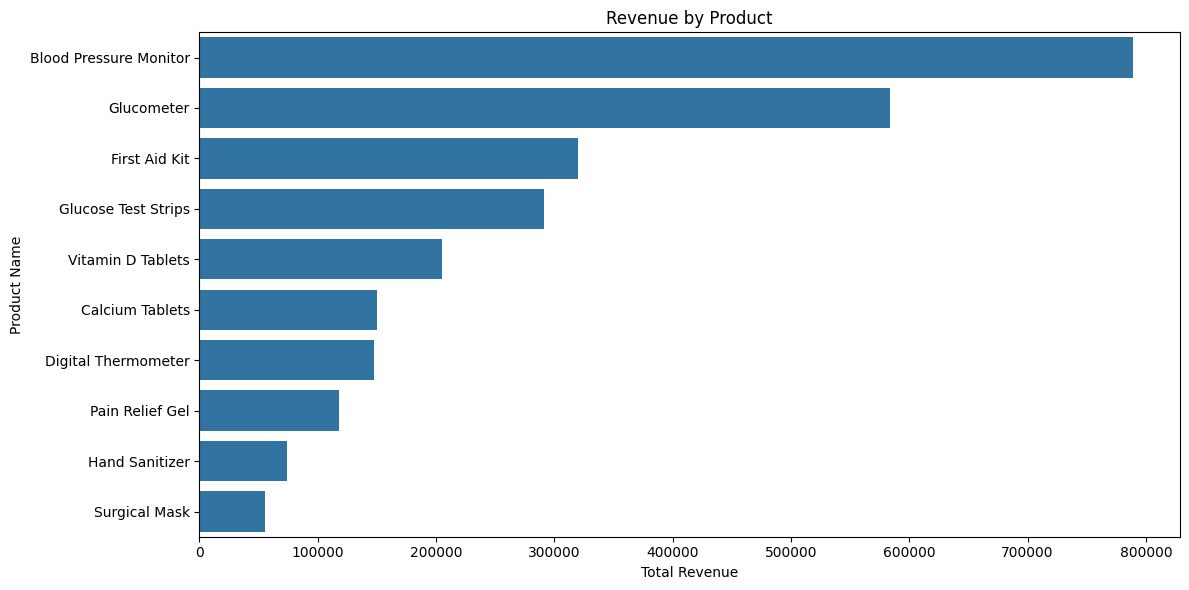

In [19]:

# ============================================================
# 5. REVENUE BY PRODUCT
# ============================================================

revenue_by_product = (
    df.groupby("product_name")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

print("\nRevenue by Product:")
print(revenue_by_product)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=revenue_by_product.values,
    y=revenue_by_product.index
)

plt.title("Revenue by Product")
plt.xlabel("Total Revenue")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()


In [24]:
df.groupby("product_name")["total_amount"].sum().sort_values(ascending=False)

product_name
Blood Pressure Monitor    789390.0
Glucometer                583440.0
First Aid Kit             319837.5
Glucose Test Strips       290972.5
Vitamin D Tablets         205245.0
Calcium Tablets           150030.0
Digital Thermometer       147420.0
Pain Relief Gel           118350.0
Hand Sanitizer             74376.0
Surgical Mask              55752.0
Name: total_amount, dtype: float64


Monthly Order Value:
year_month
2025-01     70073.0
2025-02     97824.5
2025-03     95959.0
2025-04     59099.0
2025-05     97199.0
2025-06    113739.0
2025-07     95406.0
2025-08     80972.5
2025-09     64388.0
2025-10     71692.5
2025-11    103134.0
2025-12     79402.5
2026-01     80988.5
2026-02     77706.0
2026-03     73358.5
2026-04     75812.5
2026-05     68877.0
2026-06     76460.0
2026-07     59576.0
2026-08     90009.5
2026-09     88241.0
2026-10     75961.5
2026-11     86549.0
2026-12     65728.5
2027-01     86121.0
2027-02     96329.5
2027-03     93054.5
2027-04     80363.0
2027-05     97947.0
2027-06     79219.0
2027-07     96125.0
2027-08     76213.0
2027-09     81284.0
Name: total_amount, dtype: float64


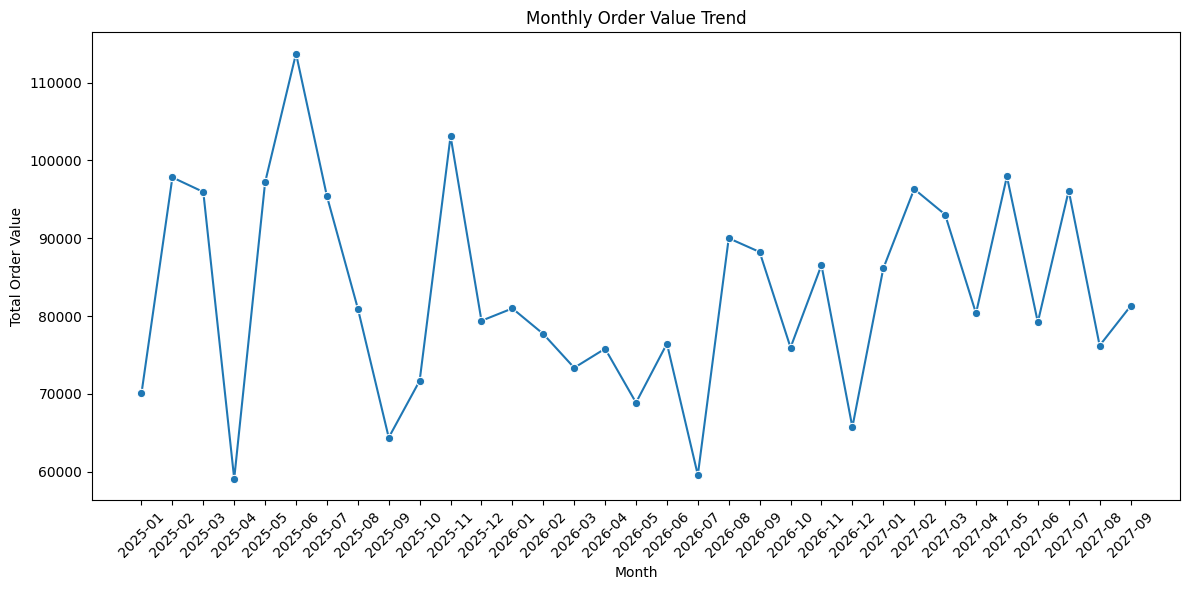

In [25]:

# ============================================================
# 6. MONTHLY SALES TREND
# ============================================================

# Convert order_date into datetime format
df["order_date"] = pd.to_datetime(df["order_date"])

# Extract year and month
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

# Calculate monthly order value
monthly_sales = (
    df.groupby("year_month")["total_amount"]
    .sum()
    .sort_index()
)

print("\nMonthly Order Value:")
print(monthly_sales)

# Plot the trend
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Monthly Order Value Trend")
plt.xlabel("Month")
plt.ylabel("Total Order Value")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [26]:
df["order_date"].dt.to_period("M").astype(str)

0      2025-01
1      2025-01
2      2025-01
3      2025-01
4      2025-01
        ...   
995    2027-09
996    2027-09
997    2027-09
998    2027-09
999    2027-09
Name: order_date, Length: 1000, dtype: object

In [27]:
df.groupby("year_month")["total_amount"].sum()

year_month
2025-01     70073.0
2025-02     97824.5
2025-03     95959.0
2025-04     59099.0
2025-05     97199.0
2025-06    113739.0
2025-07     95406.0
2025-08     80972.5
2025-09     64388.0
2025-10     71692.5
2025-11    103134.0
2025-12     79402.5
2026-01     80988.5
2026-02     77706.0
2026-03     73358.5
2026-04     75812.5
2026-05     68877.0
2026-06     76460.0
2026-07     59576.0
2026-08     90009.5
2026-09     88241.0
2026-10     75961.5
2026-11     86549.0
2026-12     65728.5
2027-01     86121.0
2027-02     96329.5
2027-03     93054.5
2027-04     80363.0
2027-05     97947.0
2027-06     79219.0
2027-07     96125.0
2027-08     76213.0
2027-09     81284.0
Name: total_amount, dtype: float64


Order Status Distribution:
order_status
Completed    855
Cancelled    107
Returned      38
Name: count, dtype: int64


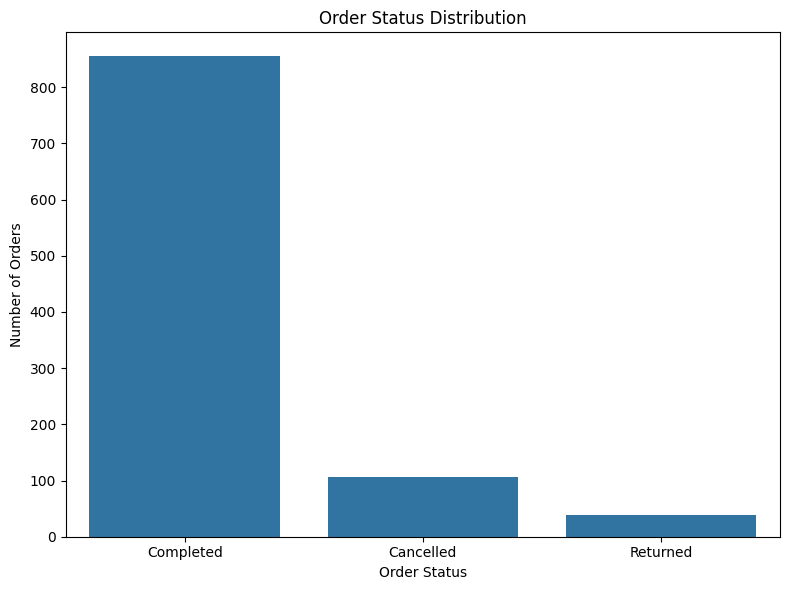


Order Status Percentages:
order_status
Completed    85.5
Cancelled    10.7
Returned      3.8
Name: proportion, dtype: float64


In [28]:

# ============================================================
# 7. ORDER STATUS DISTRIBUTION
# ============================================================

status_counts = df["order_status"].value_counts()

print("\nOrder Status Distribution:")
print(status_counts)

plt.figure(figsize=(8, 6))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

# Calculate percentages
status_percentages = (
    df["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nOrder Status Percentages:")
print(status_percentages)


In [29]:
df["order_status"].value_counts()

order_status
Completed    855
Cancelled    107
Returned      38
Name: count, dtype: int64

In [30]:
df["order_status"].value_counts(normalize=True) * 100

order_status
Completed    85.5
Cancelled    10.7
Returned      3.8
Name: proportion, dtype: float64


Correlation Matrix:
                  customer_age  quantity  discount  inventory_before  \
customer_age              1.00      0.00      0.01              0.00   
quantity                  0.00      1.00      0.01             -0.01   
discount                  0.01      0.01      1.00             -0.01   
inventory_before          0.00     -0.01     -0.01              1.00   
unit_price               -0.05     -0.04      0.02             -0.01   
total_amount             -0.03      0.46     -0.06              0.00   
gross_amount             -0.03      0.47      0.01              0.00   
discount_amount          -0.00      0.34      0.50              0.01   

                  unit_price  total_amount  gross_amount  discount_amount  
customer_age           -0.05         -0.03         -0.03            -0.00  
quantity               -0.04          0.46          0.47             0.34  
discount                0.02         -0.06          0.01             0.50  
inventory_before       -0.

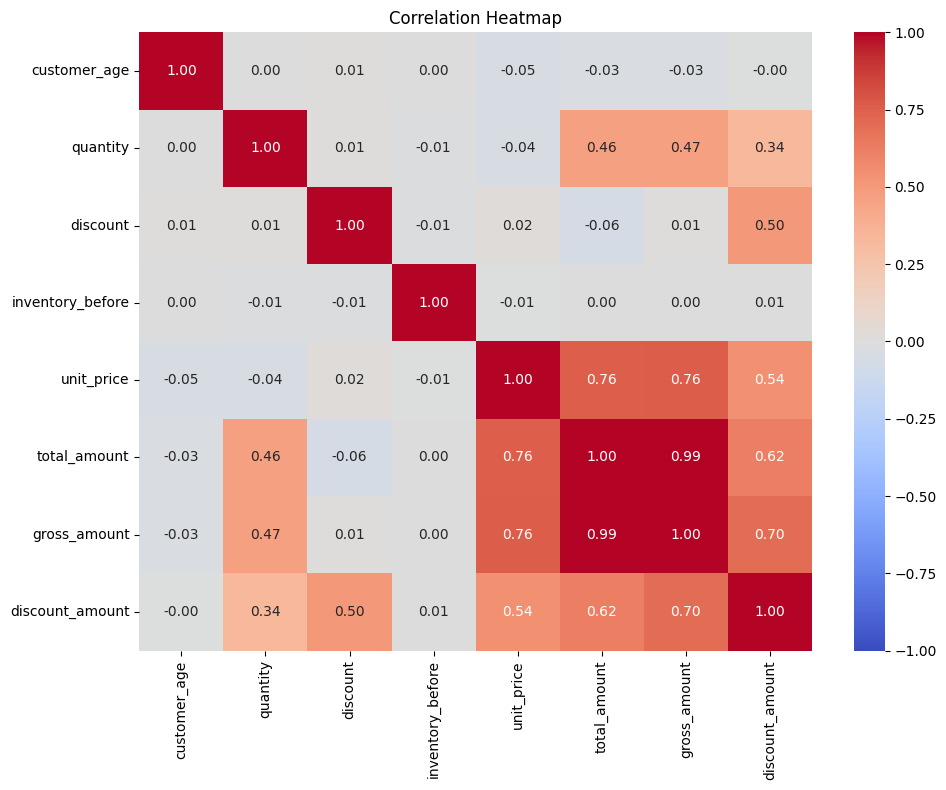

In [31]:

# ============================================================
# 8. CORRELATION ANALYSIS
# ============================================================

# Select numerical columns relevant to the analysis
numerical_columns = [
    "customer_age",
    "quantity",
    "discount",
    "inventory_before",
    "unit_price",
    "total_amount",
    "gross_amount",
    "discount_amount"
]

correlation_matrix = df[numerical_columns].corr()

print("\nCorrelation Matrix:")
print(correlation_matrix.round(2))

# Visualize correlations
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()



Outlier Visualization


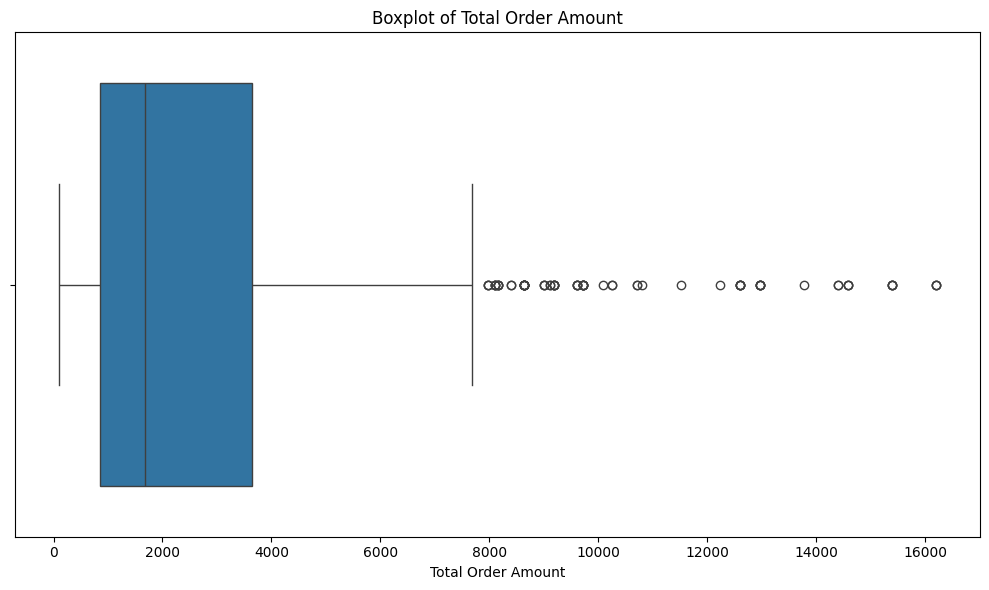


Lower IQR boundary: -3324.38
Upper IQR boundary: 7820.62
Number of outliers: 73

Top 10 highest-value orders:
               product_name  quantity  unit_price  discount  total_amount
974  Blood Pressure Monitor         9        1800         0       16200.0
170  Blood Pressure Monitor         9        1800         0       16200.0
531  Blood Pressure Monitor         9        1800         0       16200.0
929  Blood Pressure Monitor         9        1800         5       15390.0
916  Blood Pressure Monitor         9        1800         5       15390.0
308  Blood Pressure Monitor         9        1800         5       15390.0
176  Blood Pressure Monitor         9        1800         5       15390.0
770  Blood Pressure Monitor         9        1800        10       14580.0
150  Blood Pressure Monitor         9        1800        10       14580.0
681  Blood Pressure Monitor         9        1800        10       14580.0


In [32]:

# ============================================================
# 9. OUTLIER VISUALIZATION
# ============================================================

print("\nOutlier Visualization")

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="total_amount"
)

plt.title("Boxplot of Total Order Amount")
plt.xlabel("Total Order Amount")

plt.tight_layout()
plt.show()

# Display the IQR boundaries
Q1 = df["total_amount"].quantile(0.25)
Q3 = df["total_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["total_amount"] < lower_bound)
    | (df["total_amount"] > upper_bound)
]

print(f"\nLower IQR boundary: {lower_bound:.2f}")
print(f"Upper IQR boundary: {upper_bound:.2f}")
print(f"Number of outliers: {len(outliers)}")

print("\nTop 10 highest-value orders:")
print(
    outliers[
        ["product_name", "quantity", "unit_price", "discount", "total_amount"]
    ]
    .sort_values("total_amount", ascending=False)
    .head(10)
)


In [33]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Load the processed dataset
df = pd.read_csv("data/processed/cleaned_medical_orders.csv")

print("Dataset loaded successfully!")
print(f"Original shape: {df.shape}")

# Target: the quantity we want to predict
target = "quantity"

# Select features available when an order is being estimated.
# Exclude order IDs, customer IDs, and values calculated
# using the actual quantity or final order outcome.
feature_columns = [
    "product_id",
    "category",
    "unit_price",
    "discount",
    "customer_age",
    "city",
    "payment_method",
    "inventory_before",
    "month",
    "day_of_week",
    "is_weekend"
]

X = df[feature_columns]
y = df[target]

print("\nInput feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.describe())

# Convert categorical features into numerical columns
X = pd.get_dummies(
    X,
    columns=[
        "product_id",
        "category",
        "city",
        "payment_method"
    ],
    dtype=int
)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nML dataset preparation completed!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
print("\nFeatures used by the model:")
print(X.columns.tolist())


Dataset loaded successfully!
Original shape: (1000, 26)

Input feature shape: (1000, 11)
Target shape: (1000,)

Target distribution:
count    1000.000000
mean        5.030000
std         2.555706
min         1.000000
25%         3.000000
50%         5.000000
75%         7.000000
max         9.000000
Name: quantity, dtype: float64

ML dataset preparation completed!
Training features: (800, 33)
Testing features: (200, 33)
Training target: (800,)
Testing target: (200,)

Features used by the model:
['unit_price', 'discount', 'customer_age', 'inventory_before', 'month', 'day_of_week', 'is_weekend', 'product_id_P001', 'product_id_P002', 'product_id_P003', 'product_id_P004', 'product_id_P005', 'product_id_P006', 'product_id_P007', 'product_id_P008', 'product_id_P009', 'product_id_P010', 'category_Diabetes Care', 'category_Diagnostics', 'category_First Aid', 'category_Pain Relief', 'category_Personal Care', 'category_Supplements', 'city_Chennai', 'city_Coimbatore', 'city_Madurai', 'city_Salem'

In [34]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load processed data
df = pd.read_csv("data/processed/cleaned_medical_orders.csv")

# 2. Define input features and target
feature_columns = [
    "product_id",
    "category",
    "unit_price",
    "discount",
    "customer_age",
    "city",
    "payment_method",
    "inventory_before",
    "month",
    "day_of_week",
    "is_weekend"
]

target = "quantity"

X = df[feature_columns]
y = df[target]

# 3. Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["product_id", "category", "city", "payment_method"],
    dtype=int
)

# 4. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 5. Create and train the model
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

# 6. Predict quantities for the test dataset
y_pred = model.predict(X_test)

# 7. Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation Results")
print("------------------------")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

# 8. Compare with a simple baseline
baseline_prediction = [y_train.mean()] * len(y_test)

baseline_mae = mean_absolute_error(y_test, baseline_prediction)

print("\nBaseline Comparison")
print("-------------------")
print(f"Baseline MAE: {baseline_mae:.4f}")
print(f"Model MAE:    {mae:.4f}")

if mae < baseline_mae:
    print("The model improved on the baseline MAE.")
else:
    print("The model did not improve on the baseline MAE.")

# 9. Compare actual and predicted values
results = pd.DataFrame({
    "Actual_Quantity": y_test.to_numpy(),
    "Predicted_Quantity": y_pred.round(2)
})

print("\nSample Predictions:")
print(results.head(10).to_string(index=False))


Linear Regression model trained successfully!

Model Evaluation Results
------------------------
MAE:  2.3179
MSE:  7.0232
RMSE: 2.6501
R2 Score: -0.0447

Baseline Comparison
-------------------
Baseline MAE: 2.2650
Model MAE:    2.3179
The model did not improve on the baseline MAE.

Sample Predictions:
 Actual_Quantity  Predicted_Quantity
               3                5.23
               2                4.95
               1                5.34
               2                4.49
               8                5.13
               8                4.47
               5                5.56
               7                5.01
               9                5.22
               3                5.38


In [35]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv("data/processed/cleaned_medical_orders.csv")

# 2. Define features and target
feature_columns = [
    "product_id",
    "category",
    "unit_price",
    "discount",
    "customer_age",
    "city",
    "payment_method",
    "inventory_before",
    "month",
    "day_of_week",
    "is_weekend"
]

X = df[feature_columns]
y = df["quantity"]

# 3. Encode categorical features
X = pd.get_dummies(
    X,
    columns=["product_id", "category", "city", "payment_method"],
    dtype=int
)

# 4. Use the same split for a fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 5. Define models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=5,
        n_jobs=-1
    )
}

results = []

# 6. Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = mse ** 0.5
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4)
    })

# 7. Baseline: always predict the training mean
baseline_predictions = [y_train.mean()] * len(y_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

results.append({
    "Model": "Mean Baseline",
    "MAE": round(baseline_mae, 4),
    "RMSE": round(
        mean_squared_error(y_test, baseline_predictions) ** 0.5,
        4
    ),
    "R2": round(
        r2_score(y_test, baseline_predictions),
        4
    )
})

# 8. Compare results
results_df = pd.DataFrame(results)

print("\nRegression Model Comparison")
print("===========================")
print(results_df.to_string(index=False))

print("\nLower MAE and RMSE are better.")
print("Higher R2 is better.")



Regression Model Comparison
            Model    MAE   RMSE      R2
Linear Regression 2.3179 2.6501 -0.0447
    Random Forest 2.3448 2.7137 -0.0954
    Mean Baseline 2.2650 2.5929 -0.0001

Lower MAE and RMSE are better.
Higher R2 is better.


In [36]:

import pandas as pd
import numpy as np

# Make random results reproducible
np.random.seed(42)

# Number of orders
number_of_orders = 1000

# Product master data
products = [
    ("P001", "Glucometer", "Diabetes Care", 1200),
    ("P002", "Glucose Test Strips", "Diabetes Care", 650),
    ("P003", "Blood Pressure Monitor", "Diagnostics", 1800),
    ("P004", "Digital Thermometer", "Diagnostics", 350),
    ("P005", "Vitamin D Tablets", "Supplements", 450),
    ("P006", "Calcium Tablets", "Supplements", 300),
    ("P007", "Hand Sanitizer", "Personal Care", 180),
    ("P008", "Surgical Mask", "Personal Care", 120),
    ("P009", "Pain Relief Gel", "Pain Relief", 250),
    ("P010", "First Aid Kit", "First Aid", 750)
]

product_df = pd.DataFrame(
    products,
    columns=["product_id", "product_name", "category", "unit_price"]
)

# Generate order dates and input features
order_dates = pd.date_range(
    start="2025-01-01",
    periods=number_of_orders,
    freq="D"
)

product_ids = np.random.choice(
    product_df["product_id"],
    number_of_orders
)

discounts = np.random.choice(
    [0, 5, 10, 15, 20],
    number_of_orders
)

inventory = np.random.randint(
    10, 200,
    number_of_orders
)

# Base demand assumptions for each product
base_demand = {
    "P001": 3,
    "P002": 6,
    "P003": 2,
    "P004": 5,
    "P005": 4,
    "P006": 5,
    "P007": 7,
    "P008": 8,
    "P009": 4,
    "P010": 3
}

# Create learnable demand patterns
base_quantity = np.array([
    base_demand[product_id]
    for product_id in product_ids
])

# Assumption: higher discounts can increase quantity
discount_effect = discounts * 0.12

# Assumption: demand changes slightly by month
months = order_dates.month.to_numpy()

seasonal_effect = np.where(
    np.isin(months, [10, 11, 12]),
    1.0,
    0.0
)

# Random variation to keep the data realistic
random_noise = np.random.normal(
    loc=0,
    scale=1.2,
    size=number_of_orders
)

# Calculate final integer quantity
raw_quantity = (
    base_quantity
    + discount_effect
    + seasonal_effect
    + random_noise
)

quantity = np.rint(raw_quantity).astype(int)

# Keep quantity within valid business limits
quantity = np.maximum(quantity, 1)
quantity = np.minimum(quantity, 9)
quantity = np.minimum(quantity, inventory)

# Generate remaining order details
data = {
    "order_id": range(10001, 10001 + number_of_orders),
    "order_date": order_dates,

    "customer_id": np.random.randint(
        1001, 1201, number_of_orders
    ),

    "customer_age": np.random.randint(
        18, 75, number_of_orders
    ),

    "gender": np.random.choice(
        ["Male", "Female"],
        number_of_orders
    ),

    "city": np.random.choice(
        ["Chennai", "Coimbatore", "Tiruppur",
         "Madurai", "Salem", "Trichy"],
        number_of_orders
    ),

    "product_id": product_ids,
    "quantity": quantity,
    "discount": discounts,

    "payment_method": np.random.choice(
        ["UPI", "Credit Card", "Debit Card", "COD"],
        number_of_orders
    ),

    "inventory_before": inventory,

    "order_status": np.random.choice(
        ["Completed", "Cancelled", "Returned"],
        number_of_orders,
        p=[0.85, 0.10, 0.05]
    )
}

orders_df = pd.DataFrame(data)

# Add product information
orders_df = orders_df.merge(
    product_df,
    on="product_id",
    how="left"
)

# Calculate total order amount
orders_df["total_amount"] = (
    orders_df["unit_price"]
    * orders_df["quantity"]
    * (1 - orders_df["discount"] / 100)
)

# Save dataset
output_file = "data/raw/medical_ecommerce_orders.csv"

orders_df.to_csv(
    output_file,
    index=False
)

print("Dataset created successfully!")
print(f"Rows: {orders_df.shape[0]}")
print(f"Columns: {orders_df.shape[1]}")
print(f"Saved to: {output_file}")

print("\nQuantity Summary:")
print(orders_df["quantity"].describe())

print("\nAverage Quantity by Product:")
print(
    orders_df.groupby("product_name")["quantity"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("\nAverage Quantity by Discount:")
print(
    orders_df.groupby("discount")["quantity"]
    .mean()
    .round(2)
)


Dataset created successfully!
Rows: 1000
Columns: 16
Saved to: data/raw/medical_ecommerce_orders.csv

Quantity Summary:
count    1000.000000
mean        5.854000
std         2.153444
min         1.000000
25%         4.000000
50%         6.000000
75%         8.000000
max         9.000000
Name: quantity, dtype: float64

Average Quantity by Product:
product_name
Surgical Mask             8.66
Hand Sanitizer            7.89
Glucose Test Strips       7.18
Digital Thermometer       6.46
Calcium Tablets           6.40
Vitamin D Tablets         5.61
Pain Relief Gel           5.18
Glucometer                4.54
First Aid Kit             4.42
Blood Pressure Monitor    3.17
Name: quantity, dtype: float64

Average Quantity by Discount:
discount
0     4.79
5     5.46
10    5.78
15    6.32
20    6.96
Name: quantity, dtype: float64


In [37]:
import pandas as pd


# ============================================================
# 1. LOAD RAW DATA
# ============================================================

input_file = "data/raw/medical_ecommerce_orders.csv"

df = pd.read_csv(input_file)

print("Raw dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")


# ============================================================
# 2. CHECK DATA TYPES
# ============================================================

print("\nData types before preprocessing:")
print(df.dtypes)


# ============================================================
# 3. CHECK MISSING VALUES
# ============================================================

print("\nMissing values:")
print(df.isnull().sum())


# ============================================================
# 4. CHECK DUPLICATES
# ============================================================

print("\nDuplicate rows:")
print(df.duplicated().sum())

# ============================================================
# 5. CONVERT ORDER DATE
# ============================================================

df["order_date"] = pd.to_datetime(df["order_date"])

print("\nData type after converting order_date:")
print(df["order_date"].dtype)

# ============================================================
# 6. VALIDATE NUMERICAL VALUES
# ============================================================

print("\nInvalid customer ages:")
print(df[(df["customer_age"] < 18) | (df["customer_age"] > 100)])

print("\nInvalid quantities:")
print(df[df["quantity"] <= 0])

print("\nInvalid discounts:")
print(df[(df["discount"] < 0) | (df["discount"] > 100)])

print("\nInvalid unit prices:")
print(df[df["unit_price"] <= 0])

print("\nInvalid inventory values:")
print(df[df["inventory_before"] < 0])

# ============================================================
# 7. CHECK DUPLICATE ORDER IDS
# ============================================================

duplicate_order_ids = df[df["order_id"].duplicated()]

print("\nDuplicate order IDs:")
print(duplicate_order_ids)

print(
    f"Number of duplicate order IDs: "
    f"{df['order_id'].duplicated().sum()}"
)

# ============================================================
# 8. OUTLIER DETECTION USING IQR
# ============================================================

Q1 = df["total_amount"].quantile(0.25)
Q3 = df["total_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\nTotal Amount Outlier Analysis")
print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

outliers = df[
    (df["total_amount"] < lower_bound)
    | (df["total_amount"] > upper_bound)
]

print(f"Number of total_amount outliers: {len(outliers)}")

# ============================================================
# 9. CHECK CATEGORICAL VALUES
# ============================================================

categorical_columns = [
    "gender",
    "city",
    "payment_method",
    "order_status",
    "category"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())

print("\nOrder Status Distribution:")
print(df["order_status"].value_counts())

print("\nPayment Method Distribution:")
print(df["payment_method"].value_counts())

print("\nCity Distribution:")
print(df["city"].value_counts())

print("\nCategory Distribution:")
print(df["category"].value_counts())

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["day"] = df["order_date"].dt.day
df["day_of_week"] = df["order_date"].dt.dayofweek

df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

df["gross_amount"] = (
    df["unit_price"] * df["quantity"]
)

df["discount_amount"] = (
    df["gross_amount"] * df["discount"] / 100
)

df["calculated_total"] = (
    df["gross_amount"] - df["discount_amount"]
)


df["is_high_value_order"] = (
    df["total_amount"] > upper_bound
).astype(int)

df["amount_difference"] = (
    df["total_amount"] - df["calculated_total"]
)

print("\nMaximum amount calculation difference:")
print(df["amount_difference"].abs().max())

print("\nHigh-value order distribution:")
print(df["is_high_value_order"].value_counts())
output_file = "data/processed/cleaned_medical_orders.csv"

df.to_csv(output_file, index=False)

print("\nProcessed dataset saved successfully!")
print(f"Saved to: {output_file}")

print("\nSample total_amount outliers:")

print(
    outliers[
        [
            "order_id",
            "product_name",
            "category",
            "quantity",
            "discount",
            "unit_price",
            "total_amount",
            "order_status"
        ]
    ].sort_values(
        "total_amount",
        ascending=False
    ).head(20)
)

print(f"Number of total_amount outliers: {len(outliers)}")

# ============================================================
# 10. FEATURE ENGINEERING - DATE FEATURES
# ============================================================

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["day"] = df["order_date"].dt.day
df["day_of_week"] = df["order_date"].dt.dayofweek

df["is_weekend"] = (
    df["day_of_week"].isin([5, 6])
).astype(int)

# ============================================================
# 11. SAVE PROCESSED DATA
# ============================================================

output_file = "data/processed/cleaned_medical_orders.csv"

df.to_csv(output_file, index=False)

print("\nProcessed dataset saved successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"Saved to: {output_file}")

print("\nFinal columns:")
print(df.columns.tolist())

print("\nSample processed data:")
print(
    df[
        [
            "order_date",
            "year",
            "month",
            "day_of_week",
            "is_weekend",
            "unit_price",
            "quantity",
            "gross_amount",
            "discount",
            "discount_amount",
            "total_amount",
            "is_high_value_order"
        ]
    ].head(10)
)

Raw dataset loaded successfully!
Rows: 1000
Columns: 16

Data types before preprocessing:
order_id              int64
order_date           object
customer_id           int64
customer_age          int64
gender               object
city                 object
product_id           object
quantity              int64
discount              int64
payment_method       object
inventory_before      int64
order_status         object
product_name         object
category             object
unit_price            int64
total_amount        float64
dtype: object

Missing values:
order_id            0
order_date          0
customer_id         0
customer_age        0
gender              0
city                0
product_id          0
quantity            0
discount            0
payment_method      0
inventory_before    0
order_status        0
product_name        0
category            0
unit_price          0
total_amount        0
dtype: int64

Duplicate rows:
0

Data type after converting order_date:
datetim

In [38]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv("data/processed/cleaned_medical_orders.csv")

# 2. Define features and target
feature_columns = [
    "product_id",
    "category",
    "unit_price",
    "discount",
    "customer_age",
    "city",
    "payment_method",
    "inventory_before",
    "month",
    "day_of_week",
    "is_weekend"
]

X = df[feature_columns]
y = df["quantity"]

# 3. Encode categorical features
X = pd.get_dummies(
    X,
    columns=["product_id", "category", "city", "payment_method"],
    dtype=int
)

# 4. Use the same split for a fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 5. Define models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=5,
        n_jobs=-1
    )
}

results = []

# 6. Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = mse ** 0.5
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4)
    })

# 7. Baseline: always predict the training mean
baseline_predictions = [y_train.mean()] * len(y_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

results.append({
    "Model": "Mean Baseline",
    "MAE": round(baseline_mae, 4),
    "RMSE": round(
        mean_squared_error(y_test, baseline_predictions) ** 0.5,
        4
    ),
    "R2": round(
        r2_score(y_test, baseline_predictions),
        4
    )
})

# 8. Compare results
results_df = pd.DataFrame(results)

print("\nRegression Model Comparison")
print("===========================")
print(results_df.to_string(index=False))

print("\nLower MAE and RMSE are better.")
print("Higher R2 is better.")



Regression Model Comparison
            Model    MAE   RMSE      R2
Linear Regression 0.8940 1.0919  0.7245
    Random Forest 0.8648 1.0662  0.7373
    Mean Baseline 1.7469 2.0801 -0.0000

Lower MAE and RMSE are better.
Higher R2 is better.


In [39]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Load processed dataset
df = pd.read_csv(
    "data/processed/cleaned_medical_orders.csv"
)

# Select features and target
feature_columns = [
    "product_id",
    "category",
    "unit_price",
    "discount",
    "customer_age",
    "city",
    "payment_method",
    "inventory_before",
    "month",
    "day_of_week",
    "is_weekend"
]

X = df[feature_columns]
y = df["quantity"]

# Convert categorical features to numeric columns
X = pd.get_dummies(
    X,
    columns=[
        "product_id",
        "category",
        "city",
        "payment_method"
    ],
    dtype=int
)

# Same train/test split as our previous experiment
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Train Random Forest
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=5,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Display the most important features
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 10 Important Features")
print("=========================")
print(
    importance_df.head(10).to_string(
        index=False
    )
)



Top 10 Important Features
               Feature  Importance
            unit_price    0.547006
              discount    0.155218
category_Personal Care    0.071416
                 month    0.044872
          customer_age    0.032056
      inventory_before    0.030279
           day_of_week    0.014053
category_Diabetes Care    0.011531
  category_Diagnostics    0.011500
       product_id_P002    0.009947


In [40]:

import pandas as pd
import numpy as np

np.random.seed(42)

number_of_claims = 1000

# Generate synthetic insurance claim records
df = pd.DataFrame({
    "claim_id": range(50001, 50001 + number_of_claims),

    "customer_age": np.random.randint(
        18, 75, number_of_claims
    ),

    "policy_type": np.random.choice(
        ["Basic", "Standard", "Premium"],
        number_of_claims,
        p=[0.35, 0.40, 0.25]
    ),

    "policy_tenure_years": np.random.randint(
        1, 16, number_of_claims
    ),

    "claim_amount": np.random.randint(
        500, 50001, number_of_claims
    ),

    "documents_complete": np.random.choice(
        [0, 1],
        number_of_claims,
        p=[0.20, 0.80]
    ),

    "previous_claims": np.random.poisson(
        lam=1.5,
        size=number_of_claims
    )
})

# Create a synthetic review-risk score.
# These weights are illustrative assumptions, not
# validated insurance rules.
risk_score = (
    1.5 * (df["documents_complete"] == 0).astype(int)
    + 0.8 * (df["claim_amount"] > 30000).astype(int)
    + 0.4 * (df["previous_claims"] >= 3).astype(int)
    - 0.3 * (df["policy_tenure_years"] >= 5).astype(int)
    + np.random.normal(0, 0.7, number_of_claims)
)

# Binary target: 1 = flag for review, 0 = routine
df["review_flag"] = (risk_score > 1.0).astype(int)

output_file = "data/raw/insurance_claims.csv"

df.to_csv(output_file, index=False)

print("Synthetic insurance dataset created!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nReview Flag Distribution:")
print(df["review_flag"].value_counts())

print("\nReview Flag Percentage:")
print(
    (df["review_flag"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nFirst 5 Records:")
print(df.head())


Synthetic insurance dataset created!
Rows: 1000
Columns: 8

Review Flag Distribution:
review_flag
0    726
1    274
Name: count, dtype: int64

Review Flag Percentage:
review_flag
0    72.6
1    27.4
Name: proportion, dtype: float64

First 5 Records:
   claim_id  customer_age policy_type  policy_tenure_years  claim_amount  \
0     50001            56    Standard                   13         11705   
1     50002            69       Basic                    9          6406   
2     50003            46    Standard                   14          3091   
3     50004            32       Basic                    9         15649   
4     50005            60       Basic                    2         45418   

   documents_complete  previous_claims  review_flag  
0                   1                3            0  
1                   1                2            0  
2                   1                1            0  
3                   1                0            0  
4                   1  

In [41]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Load synthetic insurance claims
df = pd.read_csv("data/raw/insurance_claims.csv")

print("Dataset shape:", df.shape)

# Check missing values and duplicates
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Separate features and target
# claim_id is an identifier, not a predictive feature
target = "review_flag"

feature_columns = [
    "customer_age",
    "policy_type",
    "policy_tenure_years",
    "claim_amount",
    "documents_complete",
    "previous_claims"
]

X = df[feature_columns]
y = df[target]

# Convert policy_type into numeric columns
X = pd.get_dummies(
    X,
    columns=["policy_type"],
    dtype=int
)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nFeatures after encoding:")
print(X.columns.tolist())

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Save the prepared datasets
X_train.to_csv(
    "data/processed/insurance_X_train.csv",
    index=False
)

X_test.to_csv(
    "data/processed/insurance_X_test.csv",
    index=False
)

y_train.to_frame().to_csv(
    "data/processed/insurance_y_train.csv",
    index=False
)

y_test.to_frame().to_csv(
    "data/processed/insurance_y_test.csv",
    index=False
)

print("\nPrepared insurance datasets saved successfully!")


Dataset shape: (1000, 8)

Missing values:
claim_id               0
customer_age           0
policy_type            0
policy_tenure_years    0
claim_amount           0
documents_complete     0
previous_claims        0
review_flag            0
dtype: int64

Duplicate rows: 0

Features after encoding:
['customer_age', 'policy_tenure_years', 'claim_amount', 'documents_complete', 'previous_claims', 'policy_type_Basic', 'policy_type_Premium', 'policy_type_Standard']

Training feature shape: (800, 8)
Testing feature shape: (200, 8)

Training target distribution:
review_flag
0    581
1    219
Name: count, dtype: int64

Testing target distribution:
review_flag
0    145
1     55
Name: count, dtype: int64

Prepared insurance datasets saved successfully!


In [42]:

import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load prepared datasets
X_train = pd.read_csv(
    "data/processed/insurance_X_train.csv"
)
X_test = pd.read_csv(
    "data/processed/insurance_X_test.csv"
)

y_train = pd.read_csv(
    "data/processed/insurance_y_train.csv"
)["review_flag"]

y_test = pd.read_csv(
    "data/processed/insurance_y_test.csv"
)["review_flag"]

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate each model
for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": round(
            accuracy_score(y_test, predictions), 4
        ),
        "Precision": round(
            precision_score(
                y_test, predictions, zero_division=0
            ), 4
        ),
        "Recall": round(
            recall_score(
                y_test, predictions, zero_division=0
            ), 4
        ),
        "F1 Score": round(
            f1_score(
                y_test, predictions, zero_division=0
            ), 4
        )
    })

    print(f"\n{'=' * 45}")
    print(f"Model: {name}")
    print("=" * 45)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["Routine (0)", "Review Flag (1)"],
        zero_division=0
    ))

# Majority-class baseline
baseline_predictions = [0] * len(y_test)

results.append({
    "Model": "Majority Baseline",
    "Accuracy": round(
        accuracy_score(y_test, baseline_predictions), 4
    ),
    "Precision": round(
        precision_score(
            y_test, baseline_predictions, zero_division=0
        ), 4
    ),
    "Recall": round(
        recall_score(
            y_test, baseline_predictions, zero_division=0
        ), 4
    ),
    "F1 Score": round(
        f1_score(
            y_test, baseline_predictions, zero_division=0
        ), 4
    )
})

# Compare all models
results_df = pd.DataFrame(results)

print("\n\nClassification Model Comparison")
print("================================")
print(results_df.to_string(index=False))

print("\nFor the review class, higher recall means fewer")
print("flagged claims are missed.")
print("Higher precision means fewer routine claims are")
print("incorrectly flagged.")



Model: Logistic Regression

Confusion Matrix:
[[136   9]
 [ 30  25]]

Classification Report:
                 precision    recall  f1-score   support

    Routine (0)       0.82      0.94      0.87       145
Review Flag (1)       0.74      0.45      0.56        55

       accuracy                           0.81       200
      macro avg       0.78      0.70      0.72       200
   weighted avg       0.80      0.81      0.79       200


Model: Random Forest

Confusion Matrix:
[[140   5]
 [ 25  30]]

Classification Report:
                 precision    recall  f1-score   support

    Routine (0)       0.85      0.97      0.90       145
Review Flag (1)       0.86      0.55      0.67        55

       accuracy                           0.85       200
      macro avg       0.85      0.76      0.78       200
   weighted avg       0.85      0.85      0.84       200



Classification Model Comparison
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.805     0

In [43]:

import pandas as pd
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load prepared training and testing datasets
X_train = pd.read_csv("data/processed/insurance_X_train.csv")
X_test = pd.read_csv("data/processed/insurance_X_test.csv")

y_train = pd.read_csv("data/processed/insurance_y_train.csv")["review_flag"]
y_test = pd.read_csv("data/processed/insurance_y_test.csv")["review_flag"]

# Train the Random Forest model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Save the trained model
joblib.dump(model, "models/insurance_random_forest.pkl")

print("Model saved successfully!")
print("Location: models/insurance_random_forest.pkl")

# Evaluate the saved model's current in-memory counterpart
predictions = model.predict(X_test)

print("\nTest Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        predictions,
        target_names=["Routine (0)", "Review Flag (1)"],
        zero_division=0
    )
)

# Analyze feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 10 Important Features")
print("=========================")
print(importance_df.head(10).to_string(index=False))

# Save feature importance results
importance_df.to_csv(
    "data/processed/insurance_feature_importance.csv",
    index=False
)

print("\nFeature importance saved successfully!")


Model saved successfully!
Location: models/insurance_random_forest.pkl

Test Accuracy: 0.85

Classification Report:
                 precision    recall  f1-score   support

    Routine (0)       0.85      0.97      0.90       145
Review Flag (1)       0.86      0.55      0.67        55

       accuracy                           0.85       200
      macro avg       0.85      0.76      0.78       200
   weighted avg       0.85      0.85      0.84       200


Top 10 Important Features
             Feature  Importance
  documents_complete    0.445882
        claim_amount    0.258639
 policy_tenure_years    0.098544
        customer_age    0.096925
     previous_claims    0.063706
   policy_type_Basic    0.013552
policy_type_Standard    0.013007
 policy_type_Premium    0.009745

Feature importance saved successfully!


In [45]:

import pandas as pd
import joblib

# Load the saved model
model = joblib.load("models/insurance_random_forest.pkl")

# Example synthetic insurance claim
new_claim = pd.DataFrame([{
    "customer_age": 45,
    "policy_tenure_years": 3,
    "claim_amount": 42000,
    "documents_complete": 0,
    "previous_claims": 3,
    "policy_type_Basic": 0,
    "policy_type_Premium": 0,
    "policy_type_Standard": 1
}])

# Match the exact feature order used during training
new_claim = new_claim[model.feature_names_in_]

prediction = model.predict(new_claim)[0]
probabilities = model.predict_proba(new_claim)[0]

print("Predicted class:", prediction)
print("Probability of Routine:", round(probabilities[0], 4))
print("Probability of Review Flag:", round(probabilities[1], 4))

if prediction == 1:
    print("Result: Flag for human review")
else:
    print("Result: Routine classification")

print("\nNote: This is a synthetic demonstration, not a real claim decision.")


Predicted class: 1
Probability of Routine: 0.1092
Probability of Review Flag: 0.8908
Result: Flag for human review

Note: This is a synthetic demonstration, not a real claim decision.


In [46]:

import pandas as pd

file_path = "data/processed/cleaned_medical_orders.csv"

df = pd.read_csv(file_path)

print("=" * 50)
print("CUSTOMER SEGMENTATION - DATA INSPECTION")
print("=" * 50)

print("\nDataset shape:")
print(df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
print(df.head())

print("\nCustomer ID check:")
if "customer_id" in df.columns:
    print("Unique customers:", df["customer_id"].nunique())
    print("Missing customer IDs:", df["customer_id"].isna().sum())
else:
    print("customer_id column not found!")

print("\nMissing values in important columns:")
for col in [
    "customer_id",
    "quantity",
    "total_amount",
    "order_status"
]:
    if col in df.columns:
        print(f"{col}: {df[col].isna().sum()}")

print("\nData inspection completed.")


CUSTOMER SEGMENTATION - DATA INSPECTION

Dataset shape:
(1000, 26)

Available columns:
['order_id', 'order_date', 'customer_id', 'customer_age', 'gender', 'city', 'product_id', 'quantity', 'discount', 'payment_method', 'inventory_before', 'order_status', 'product_name', 'category', 'unit_price', 'total_amount', 'year', 'month', 'day', 'day_of_week', 'is_weekend', 'gross_amount', 'discount_amount', 'calculated_total', 'is_high_value_order', 'amount_difference']

First 5 records:
   order_id  order_date  customer_id  customer_age  gender     city  \
0     10001  2025-01-01         1184            73  Female    Salem   
1     10002  2025-01-02         1090            42  Female   Trichy   
2     10003  2025-01-03         1094            49    Male  Madurai   
3     10004  2025-01-04         1013            50  Female   Trichy   
4     10005  2025-01-05         1066            62    Male  Madurai   

  product_id  quantity  discount payment_method  ...  year month day  \
0       P007      

In [47]:

import pandas as pd

# Load the cleaned order dataset
input_path = "data/processed/cleaned_medical_orders.csv"
output_path = "data/processed/customer_segmentation_data.csv"

df = pd.read_csv(input_path)

# Validate required columns
required_columns = [
    "customer_id",
    "order_id",
    "total_amount",
    "quantity",
    "discount",
    "product_id",
    "order_status"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Aggregate order data into one row per customer
customer_df = df.groupby("customer_id").agg(
    order_count=("order_id", "nunique"),
    total_spend=("total_amount", "sum"),
    avg_order_value=("total_amount", "mean"),
    total_quantity=("quantity", "sum"),
    avg_discount=("discount", "mean"),
    unique_products=("product_id", "nunique"),
    cancelled_orders=(
        "order_status",
        lambda x: (x == "Cancelled").sum()
    ),
    returned_orders=(
        "order_status",
        lambda x: (x == "Returned").sum()
    )
).reset_index()

# Save customer-level data
customer_df.to_csv(output_path, index=False)

print("=" * 50)
print("CUSTOMER SEGMENTATION DATA PREPARED")
print("=" * 50)

print("\nCustomer-level dataset shape:")
print(customer_df.shape)

print("\nFirst 10 customers:")
print(customer_df.head(10).to_string(index=False))

print("\nSummary statistics:")
print(customer_df.drop(columns=["customer_id"]).describe().round(2))

print("\nMissing values:")
print(customer_df.isnull().sum())

print("\nUnique customers:", customer_df["customer_id"].nunique())
print("\nSaved to:", output_path)


CUSTOMER SEGMENTATION DATA PREPARED

Customer-level dataset shape:
(198, 9)

First 10 customers:
 customer_id  order_count  total_spend  avg_order_value  total_quantity  avg_discount  unique_products  cancelled_orders  returned_orders
        1001            1       2160.0      2160.000000               6     20.000000                1                 0                0
        1002            3       8023.5      2674.500000              17      6.666667                3                 1                0
        1003            2       3595.5      1797.750000              16     15.000000                2                 0                0
        1004            4       9959.0      2489.750000              22     11.250000                4                 0                0
        1005            4      12562.5      3140.625000              22      7.500000                4                 0                0
        1006            7      16818.0      2402.571429              35    

In [48]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

input_path = "data/processed/customer_segmentation_data.csv"
output_path = "data/processed/customer_features_scaled.csv"

# Load customer-level dataset
df = pd.read_csv(input_path)

# Keep customer ID separately; don't use it for clustering
customer_ids = df["customer_id"]

# Select behavioral features
feature_columns = [
    "order_count",
    "total_spend",
    "avg_order_value",
    "total_quantity",
    "avg_discount",
    "unique_products",
    "cancelled_orders",
    "returned_orders"
]

X = df[feature_columns].copy()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert scaled data back to a DataFrame
scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns
)

# Add customer ID only for tracking results
scaled_df.insert(0, "customer_id", customer_ids.values)

# Save scaled dataset
scaled_df.to_csv(output_path, index=False)

print("=" * 50)
print("CUSTOMER FEATURES SCALED")
print("=" * 50)

print("\nScaled dataset shape:", scaled_df.shape)

print("\nFirst 5 scaled records:")
print(scaled_df.head().round(3).to_string(index=False))

print("\nFeature means after scaling:")
print(scaled_df[feature_columns].mean().round(3))

print("\nFeature standard deviations after scaling:")
print(scaled_df[feature_columns].std(ddof=0).round(3))

print("\nSaved to:", output_path)


CUSTOMER FEATURES SCALED

Scaled dataset shape: (198, 9)

First 5 scaled records:
 customer_id  order_count  total_spend  avg_order_value  total_quantity  avg_discount  unique_products  cancelled_orders  returned_orders
        1001       -1.834       -1.677           -0.636          -1.779         2.734           -1.908            -0.742           -0.498
        1002       -0.929       -0.820           -0.024          -0.948        -0.953           -0.645             0.618           -0.498
        1003       -1.381       -1.468           -1.066          -1.024         1.351           -1.277            -0.742           -0.498
        1004       -0.476       -0.537           -0.244          -0.571         0.314           -0.013            -0.742           -0.498
        1005       -0.476       -0.157            0.529          -0.571        -0.723           -0.013            -0.742           -0.498

Feature means after scaling:
order_count         0.0
total_spend        -0.0
avg_order_va

In [49]:

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

input_path = "data/processed/customer_features_scaled.csv"

df = pd.read_csv(input_path)

# Keep IDs for reporting, but exclude them from clustering
customer_ids = df["customer_id"]

feature_columns = [
    "order_count",
    "total_spend",
    "avg_order_value",
    "total_quantity",
    "avg_discount",
    "unique_products",
    "cancelled_orders",
    "returned_orders"
]

X = df[feature_columns]

# Evaluate candidate cluster counts
inertias = []
silhouette_scores = []
k_values = range(2, 9)

print("=" * 55)
print("K-MEANS CUSTOMER CLUSTER EVALUATION")
print("=" * 55)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

    print(
        f"k={k} | "
        f"Inertia={model.inertia_:.2f} | "
        f"Silhouette Score={score:.4f}"
    )

# Save evaluation results
evaluation_df = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})

evaluation_df.to_csv(
    "data/processed/kmeans_evaluation.csv",
    index=False
)

# Plot the Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.savefig(
    "data/processed/kmeans_elbow.png",
    dpi=150
)
plt.close()

# Train initial candidate model with 4 clusters
final_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = final_model.fit_predict(X)

# Save the cluster assignment for every customer
results_df = pd.DataFrame({
    "customer_id": customer_ids,
    "cluster": cluster_labels
})

results_df.to_csv(
    "data/processed/customer_clusters.csv",
    index=False
)

print("\nInitial model trained with 4 clusters.")
print("\nCustomer count per cluster:")
print(results_df["cluster"].value_counts().sort_index())

print("\nSaved files:")
print("- data/processed/kmeans_evaluation.csv")
print("- data/processed/kmeans_elbow.png")
print("- data/processed/customer_clusters.csv")


K-MEANS CUSTOMER CLUSTER EVALUATION
k=2 | Inertia=1089.24 | Silhouette Score=0.2628
k=3 | Inertia=947.99 | Silhouette Score=0.1778
k=4 | Inertia=828.23 | Silhouette Score=0.2113
k=5 | Inertia=731.81 | Silhouette Score=0.2042
k=6 | Inertia=671.70 | Silhouette Score=0.2026
k=7 | Inertia=614.71 | Silhouette Score=0.2105
k=8 | Inertia=559.04 | Silhouette Score=0.2250

Initial model trained with 4 clusters.

Customer count per cluster:
cluster
0    48
1    74
2    32
3    44
Name: count, dtype: int64

Saved files:
- data/processed/kmeans_evaluation.csv
- data/processed/kmeans_elbow.png
- data/processed/customer_clusters.csv


In [50]:

import pandas as pd

customer_path = "data/processed/customer_segmentation_data.csv"
cluster_path = "data/processed/customer_clusters.csv"

customers = pd.read_csv(customer_path)
clusters = pd.read_csv(cluster_path)

# Join customer behavior with cluster assignments
df = customers.merge(
    clusters,
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

profile_columns = [
    "order_count",
    "total_spend",
    "avg_order_value",
    "total_quantity",
    "avg_discount",
    "unique_products",
    "cancelled_orders",
    "returned_orders"
]

# Show average behavior for each cluster
profiles = df.groupby("cluster")[profile_columns].mean().round(2)

print("=" * 60)
print("CUSTOMER SEGMENT PROFILES — FOUR CLUSTERS")
print("=" * 60)

print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())

print("\nAverage feature values per cluster:")
print(profiles.to_string())

print("\nMedian total spend per cluster:")
print(df.groupby("cluster")["total_spend"].median().round(2))

print("\nCustomer segmentation analysis completed.")

# Save results for later reporting
profiles.to_csv(
    "data/processed/customer_segment_profiles.csv"
)

print("\nSaved to: data/processed/customer_segment_profiles.csv")


CUSTOMER SEGMENT PROFILES — FOUR CLUSTERS

Cluster sizes:
cluster
0    48
1    74
2    32
3    44
Name: count, dtype: int64

Average feature values per cluster:
         order_count  total_spend  avg_order_value  total_quantity  avg_discount  unique_products  cancelled_orders  returned_orders
cluster                                                                                                                             
0               7.79     21018.66          2717.51           45.31          9.74             5.83              1.10             0.10
1               4.73     13691.10          3017.15           27.77         10.27             3.86              0.28             0.00
2               5.53     14540.27          2628.41           32.44          9.93             4.28              0.53             1.06
3               2.25      4831.55          2176.97           13.32         10.39             2.11              0.39             0.09

Median total spend per cluster:
cluster


In [51]:

import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load customer-level behavioral features
df = pd.read_csv(
    "data/processed/customer_segmentation_data.csv"
)

feature_columns = [
    "order_count",
    "total_spend",
    "avg_order_value",
    "total_quantity",
    "avg_discount",
    "unique_products",
    "cancelled_orders",
    "returned_orders"
]

X = df[feature_columns]

# Fit and save the scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

joblib.dump(
    scaler,
    "models/customer_segmentation_scaler.pkl"
)

# Fit and save the K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

joblib.dump(
    kmeans,
    "models/customer_kmeans.pkl"
)

print("Customer segmentation model saved!")
print("Scaler: models/customer_segmentation_scaler.pkl")
print("Model: models/customer_kmeans.pkl")

print("\nCluster counts:")
print(pd.Series(clusters).value_counts().sort_index())


Customer segmentation model saved!
Scaler: models/customer_segmentation_scaler.pkl
Model: models/customer_kmeans.pkl

Cluster counts:
0    48
1    74
2    32
3    44
Name: count, dtype: int64


In [52]:

import pandas as pd
import joblib

# Load saved artifacts
scaler = joblib.load(
    "models/customer_segmentation_scaler.pkl"
)

kmeans = joblib.load(
    "models/customer_kmeans.pkl"
)

# Example customer profile using synthetic project data
feature_columns = [
    "order_count",
    "total_spend",
    "avg_order_value",
    "total_quantity",
    "avg_discount",
    "unique_products",
    "cancelled_orders",
    "returned_orders"
]

new_customer = pd.DataFrame([{
    "order_count": 7,
    "total_spend": 18000,
    "avg_order_value": 2571.43,
    "total_quantity": 35,
    "avg_discount": 10,
    "unique_products": 5,
    "cancelled_orders": 0,
    "returned_orders": 0
}])[feature_columns]

# Apply the same fitted scaler used by the model
new_customer_scaled = scaler.transform(new_customer)

# Predict the cluster
cluster = kmeans.predict(new_customer_scaled)[0]

print("=" * 50)
print("CUSTOMER SEGMENT PREDICTION")
print("=" * 50)

print("\nCustomer profile:")
print(new_customer.to_string(index=False))

print("\nPredicted cluster:", cluster)
print("Prediction completed successfully!")
print("\nNote: Cluster IDs are numeric labels, not rankings.")


CUSTOMER SEGMENT PREDICTION

Customer profile:
 order_count  total_spend  avg_order_value  total_quantity  avg_discount  unique_products  cancelled_orders  returned_orders
           7        18000          2571.43              35            10                5                 0                0

Predicted cluster: 1
Prediction completed successfully!

Note: Cluster IDs are numeric labels, not rankings.


In [53]:

import pandas as pd
import joblib

# Load customer-level data and saved model artifacts
data = pd.read_csv(
    "data/processed/customer_segmentation_data.csv"
)

scaler = joblib.load(
    "models/customer_segmentation_scaler.pkl"
)

kmeans = joblib.load(
    "models/customer_kmeans.pkl"
)

feature_columns = [
    "order_count",
    "total_spend",
    "avg_order_value",
    "total_quantity",
    "avg_discount",
    "unique_products",
    "cancelled_orders",
    "returned_orders"
]

# Assign clusters using the exact saved model
scaled_features = scaler.transform(data[feature_columns])
data["cluster"] = kmeans.predict(scaled_features)

# Summarize the actual profiles for each saved-model cluster
profile = data.groupby("cluster").agg(
    customer_count=("customer_id", "count"),
    avg_orders=("order_count", "mean"),
    avg_total_spend=("total_spend", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_unique_products=("unique_products", "mean"),
    avg_cancelled_orders=("cancelled_orders", "mean"),
    avg_returned_orders=("returned_orders", "mean")
).round(2)

print("=" * 60)
print("SAVED MODEL - CUSTOMER CLUSTER PROFILES")
print("=" * 60)
print(profile.to_string())

# Save results for project documentation
profile.to_csv(
    "data/processed/saved_model_cluster_profiles.csv"
)

print("\nProfiles saved successfully!")


SAVED MODEL - CUSTOMER CLUSTER PROFILES
         customer_count  avg_orders  avg_total_spend  avg_order_value  avg_unique_products  avg_cancelled_orders  avg_returned_orders
cluster                                                                                                                              
0                    48        7.79         21018.66          2717.51                 5.83                  1.10                 0.10
1                    74        4.73         13691.10          3017.15                 3.86                  0.28                 0.00
2                    32        5.53         14540.27          2628.41                 4.28                  0.53                 1.06
3                    44        2.25          4831.55          2176.97                 2.11                  0.39                 0.09

Profiles saved successfully!


In [1]:
#inspect_recommendation_data

import pandas as pd

file_path = "data/processed/cleaned_medical_orders.csv"

df = pd.read_csv(file_path)

print("=" * 60)
print("PRODUCT RECOMMENDATION - DATA INSPECTION")
print("=" * 60)

print("\nDataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nOrder status distribution:")
print(df["order_status"].value_counts())

print("\nUnique customers:", df["customer_id"].nunique())
print("Unique products:", df["product_id"].nunique())

print("\nCustomer-product purchase history:")
print(
    df.groupby(["customer_id", "product_id"])
      .size()
      .reset_index(name="purchase_count")
      .head(10)
)

print("\nProduct purchase summary:")
print(
    df.groupby(["product_id", "product_name"])
      .agg(
          total_orders=("order_id", "nunique"),
          total_quantity=("quantity", "sum")
      )
      .reset_index()
      .sort_values("total_orders", ascending=False)
)

print("\nData inspection completed!")


PRODUCT RECOMMENDATION - DATA INSPECTION

Dataset shape: (1000, 26)

Available columns:
['order_id', 'order_date', 'customer_id', 'customer_age', 'gender', 'city', 'product_id', 'quantity', 'discount', 'payment_method', 'inventory_before', 'order_status', 'product_name', 'category', 'unit_price', 'total_amount', 'year', 'month', 'day', 'day_of_week', 'is_weekend', 'gross_amount', 'discount_amount', 'calculated_total', 'is_high_value_order', 'amount_difference']

Order status distribution:
order_status
Completed    849
Cancelled    108
Returned      43
Name: count, dtype: int64

Unique customers: 198
Unique products: 10

Customer-product purchase history:
   customer_id product_id  purchase_count
0         1001       P005               1
1         1002       P003               1
2         1002       P005               1
3         1002       P008               1
4         1003       P005               1
5         1003       P008               1
6         1004       P002               1
7

In [2]:

import pandas as pd

# Load processed order dataset
df = pd.read_csv(
    "data/processed/cleaned_medical_orders.csv"
)

print("=" * 60)
print("PREPARING PRODUCT RECOMMENDATION DATA")
print("=" * 60)

# Keep only successfully completed orders
completed_orders = df[
    df["order_status"] == "Completed"
].copy()

print("\nCompleted orders:", len(completed_orders))

# Aggregate customer-product purchases
purchase_history = (
    completed_orders
    .groupby(["customer_id", "product_id"])
    .agg(
        purchase_count=("order_id", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

# Create customer-product interaction matrix
purchase_matrix = purchase_history.pivot_table(
    index="customer_id",
    columns="product_id",
    values="purchase_count",
    fill_value=0
)

# Convert purchase counts into binary interactions
purchase_matrix = (purchase_matrix > 0).astype(int)

# Save both datasets
purchase_history.to_csv(
    "data/processed/customer_product_history.csv",
    index=False
)

purchase_matrix.to_csv(
    "data/processed/customer_product_matrix.csv"
)

print("\nPurchase history shape:", purchase_history.shape)
print("Purchase matrix shape:", purchase_matrix.shape)

print("\nCustomer-product matrix:")
print(purchase_matrix.head(10))

print("\nTotal successful customer-product interactions:",
      int(purchase_matrix.values.sum()))

print("\nFiles saved successfully!")


PREPARING PRODUCT RECOMMENDATION DATA

Completed orders: 849

Purchase history shape: (693, 4)
Purchase matrix shape: (194, 10)

Customer-product matrix:
product_id   P001  P002  P003  P004  P005  P006  P007  P008  P009  P010
customer_id                                                            
1001            0     0     0     0     1     0     0     0     0     0
1002            0     0     1     0     1     0     0     0     0     0
1003            0     0     0     0     1     0     0     1     0     0
1004            0     1     1     0     0     0     1     0     0     1
1005            1     1     0     0     1     1     0     0     0     0
1006            1     0     1     1     0     0     0     1     0     1
1007            0     0     1     1     0     0     0     0     0     0
1008            0     0     0     0     1     1     0     0     0     1
1009            0     0     1     0     1     0     0     0     0     0
1010            0     0     0     0     0     1     0 

In [3]:

import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Load customer-product matrix
purchase_matrix = pd.read_csv(
    "data/processed/customer_product_matrix.csv",
    index_col="customer_id"
)

print("=" * 60)
print("CUSTOMER SIMILARITY ANALYSIS")
print("=" * 60)

# Calculate cosine similarity between customers
similarity_array = cosine_similarity(purchase_matrix)

# Convert similarity array into DataFrame
similarity_df = pd.DataFrame(
    similarity_array,
    index=purchase_matrix.index,
    columns=purchase_matrix.index
)

# Save similarity results
similarity_df.to_csv(
    "data/processed/customer_similarity.csv"
)

# Select a sample customer
customer_id = 1002

print("\nSimilarity scores for customer:", customer_id)

similar_customers = (
    similarity_df[customer_id]
    .drop(customer_id)
    .sort_values(ascending=False)
    .head(5)
)

print("\nTop 5 similar customers:")
print(similar_customers)

print("\nSimilarity analysis completed!")
print("\nSimilarity matrix shape:", similarity_df.shape)
print("\nFile saved: data/processed/customer_similarity.csv")


CUSTOMER SIMILARITY ANALYSIS

Similarity scores for customer: 1002

Top 5 similar customers:
customer_id
1196    1.000000
1009    1.000000
1043    0.816497
1019    0.816497
1014    0.816497
Name: 1002, dtype: float64

Similarity analysis completed!

Similarity matrix shape: (194, 194)

File saved: data/processed/customer_similarity.csv


In [5]:

import pandas as pd

# Load purchase matrix and similarity matrix
purchase_matrix = pd.read_csv(
    "data/processed/customer_product_matrix.csv",
    index_col="customer_id"
)

similarity_df = pd.read_csv(
    "data/processed/customer_similarity.csv",
    index_col="customer_id"
)

# Convert customer IDs from strings to integers
similarity_df.index = similarity_df.index.astype(int)
similarity_df.columns = similarity_df.columns.astype(int)

# Function to recommend products
def recommend_products(customer_id, top_n=5, similar_users=5):

    if customer_id not in purchase_matrix.index:
        print("Customer not found in purchase history.")
        return

    # Find most similar customers
    similar_customers = (
        similarity_df[customer_id]
        .drop(customer_id)
        .sort_values(ascending=False)
        .head(similar_users)
    )

    # Get products already purchased by target customer
    purchased_products = set(
        purchase_matrix.columns[
            purchase_matrix.loc[customer_id] > 0
        ]
    )

    # Calculate recommendation scores
    recommendation_scores = {}

    for other_customer, similarity_score in similar_customers.items():

        other_products = purchase_matrix.loc[other_customer]

        for product_id, purchased in other_products.items():

            if purchased > 0 and product_id not in purchased_products:

                recommendation_scores[product_id] = (
                    recommendation_scores.get(product_id, 0)
                    + similarity_score
                )

    # Sort recommended products
    recommendations = sorted(
        recommendation_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:top_n]

    print("\nCustomer ID:", customer_id)
    print("\nPreviously purchased products:", purchased_products)

    print("\nRecommended products:")

    if not recommendations:
        print("No new recommendations available.")
    else:
        for product_id, score in recommendations:
            print(
                f"Product: {product_id} | "
                f"Recommendation Score: {score:.4f}"
            )


# Test recommendation engine
recommend_products(customer_id=1002, top_n=5)

print("\nProduct recommendation completed!")



Customer ID: 1002

Previously purchased products: {'P003', 'P005'}

Recommended products:
Product: P002 | Recommendation Score: 0.8165
Product: P010 | Recommendation Score: 0.8165
Product: P004 | Recommendation Score: 0.8165

Product recommendation completed!


In [6]:

import pandas as pd

purchase_matrix = pd.read_csv(
    "data/processed/customer_product_matrix.csv",
    index_col="customer_id"
)

similarity_df = pd.read_csv(
    "data/processed/customer_similarity.csv",
    index_col="customer_id"
)

similarity_df.index = similarity_df.index.astype(int)
similarity_df.columns = similarity_df.columns.astype(int)

# Load product details
orders = pd.read_csv(
    "data/processed/cleaned_medical_orders.csv"
)

product_details = (
    orders[["product_id", "product_name", "category", "unit_price"]]
    .drop_duplicates(subset="product_id")
    .set_index("product_id")
)

def recommend_products(customer_id, top_n=5, similar_users=5):

    if customer_id not in purchase_matrix.index:
        print("Customer not found!")
        return

    similar_customers = (
        similarity_df.loc[customer_id]
        .drop(customer_id)
        .sort_values(ascending=False)
        .head(similar_users)
    )

    purchased_products = set(
        purchase_matrix.columns[
            purchase_matrix.loc[customer_id] > 0
        ]
    )

    scores = {}

    for other_customer, similarity_score in similar_customers.items():

        other_products = purchase_matrix.loc[other_customer]

        for product_id, purchased in other_products.items():

            if purchased > 0 and product_id not in purchased_products:

                scores[product_id] = (
                    scores.get(product_id, 0) + similarity_score
                )

    recommendations = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:top_n]

    print("\nCustomer ID:", customer_id)
    print("\nRecommended Products:")

    for product_id, score in recommendations:

        details = product_details.loc[product_id]

        print("\nProduct ID:", product_id)
        print("Product Name:", details["product_name"])
        print("Category:", details["category"])
        print("Price: Rs.", details["unit_price"])
        print("Recommendation Score:", round(score, 4))


recommend_products(1002)

print("\nRecommendation completed successfully!")



Customer ID: 1002

Recommended Products:

Product ID: P002
Product Name: Glucose Test Strips
Category: Diabetes Care
Price: Rs. 650
Recommendation Score: 0.8165

Product ID: P010
Product Name: First Aid Kit
Category: First Aid
Price: Rs. 750
Recommendation Score: 0.8165

Product ID: P004
Product Name: Digital Thermometer
Category: Diagnostics
Price: Rs. 350
Recommendation Score: 0.8165

Recommendation completed successfully!


In [7]:

import pandas as pd
import random

# Load purchase matrix
purchase_matrix = pd.read_csv(
    "data/processed/customer_product_matrix.csv",
    index_col="customer_id"
)

# Load product similarity data
similarity_df = pd.read_csv(
    "data/processed/customer_similarity.csv",
    index_col="customer_id"
)

similarity_df.index = similarity_df.index.astype(int)
similarity_df.columns = similarity_df.columns.astype(int)

random.seed(42)

def recommend_for_customer(
    customer_id,
    matrix,
    similarity,
    top_n=3,
    similar_users=5
):
    similar_customers = (
        similarity.loc[customer_id]
        .drop(customer_id)
        .sort_values(ascending=False)
        .head(similar_users)
    )

    purchased_products = set(
        matrix.columns[matrix.loc[customer_id] > 0]
    )

    scores = {}

    for other_customer, similarity_score in similar_customers.items():

        other_products = matrix.loc[other_customer]

        for product_id, purchased in other_products.items():

            if purchased > 0 and product_id not in purchased_products:
                scores[product_id] = (
                    scores.get(product_id, 0) + similarity_score
                )

    recommendations = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [product for product, score in recommendations[:top_n]]


# Evaluation
hits = 0
total_test_cases = 0
precision_sum = 0
recall_sum = 0

for customer_id in purchase_matrix.index:

    purchased_products = list(
        purchase_matrix.columns[
            purchase_matrix.loc[customer_id] > 0
        ]
    )

    # Need at least two products for a meaningful test
    if len(purchased_products) < 2:
        continue

    # Temporarily hide one purchased product
    hidden_product = random.choice(purchased_products)

    test_matrix = purchase_matrix.copy()
    test_matrix.loc[customer_id, hidden_product] = 0

    # Generate recommendations from remaining purchases
    recommendations = recommend_for_customer(
        customer_id,
        test_matrix,
        similarity_df,
        top_n=3
    )

    # Evaluate whether hidden product was recommended
    hit = int(hidden_product in recommendations)

    hits += hit
    total_test_cases += 1

    precision_sum += hit / 3
    recall_sum += hit / 1

# Display metrics
if total_test_cases > 0:

    hit_rate = hits / total_test_cases
    precision_at_3 = precision_sum / total_test_cases
    recall_at_3 = recall_sum / total_test_cases

    print("=" * 60)
    print("RECOMMENDATION MODEL EVALUATION")
    print("=" * 60)

    print("\nTotal test cases:", total_test_cases)
    print("Successful recommendations:", hits)

    print("\nHit Rate@3:", round(hit_rate, 4))
    print("Precision@3:", round(precision_at_3, 4))
    print("Recall@3:", round(recall_at_3, 4))

    print("\nEvaluation completed successfully!")

else:
    print("No eligible customers found for evaluation.")


RECOMMENDATION MODEL EVALUATION

Total test cases: 179
Successful recommendations: 179

Hit Rate@3: 1.0
Precision@3: 0.3333
Recall@3: 1.0

Evaluation completed successfully!


In [8]:

import pandas as pd
import random
from sklearn.metrics.pairwise import cosine_similarity

purchase_matrix = pd.read_csv(
    "data/processed/customer_product_matrix.csv",
    index_col="customer_id"
)

random.seed(42)

def recommend_products(customer_id, matrix, top_n=3):

    similarity_array = cosine_similarity(matrix)

    similarity_df = pd.DataFrame(
        similarity_array,
        index=matrix.index,
        columns=matrix.index
    )

    similar_customers = (
        similarity_df.loc[customer_id]
        .drop(customer_id)
        .sort_values(ascending=False)
        .head(5)
    )

    purchased_products = set(
        matrix.columns[matrix.loc[customer_id] > 0]
    )

    scores = {}

    for other_customer, similarity_score in similar_customers.items():

        other_products = matrix.loc[other_customer]

        for product_id, purchased in other_products.items():

            if purchased > 0 and product_id not in purchased_products:

                scores[product_id] = (
                    scores.get(product_id, 0) + similarity_score
                )

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [product for product, score in ranked[:top_n]]


hits = 0
total_cases = 0
precision_sum = 0

for customer_id in purchase_matrix.index:

    products = list(
        purchase_matrix.columns[
            purchase_matrix.loc[customer_id] > 0
        ]
    )

    if len(products) < 2:
        continue

    hidden_product = random.choice(products)

    test_matrix = purchase_matrix.copy()
    test_matrix.loc[customer_id, hidden_product] = 0

    recommendations = recommend_products(
        customer_id,
        test_matrix,
        top_n=3
    )

    hit = int(hidden_product in recommendations)

    hits += hit
    total_cases += 1
    precision_sum += hit / 3

if total_cases > 0:

    print("=" * 60)
    print("CORRECTED RECOMMENDATION EVALUATION")
    print("=" * 60)

    print("\nTotal test cases:", total_cases)
    print("Successful recommendations:", hits)

    print(
        "\nHit Rate@3:",
        round(hits / total_cases, 4)
    )

    print(
        "Precision@3:",
        round(precision_sum / total_cases, 4)
    )

    print("\nEvaluation completed!")

else:
    print("No eligible test cases found.")


CORRECTED RECOMMENDATION EVALUATION

Total test cases: 179
Successful recommendations: 66

Hit Rate@3: 0.3687
Precision@3: 0.1229

Evaluation completed!


In [9]:

import pandas as pd
import joblib
from sklearn.metrics.pairwise import cosine_similarity

# Load customer-product purchase matrix
purchase_matrix = pd.read_csv(
    "data/processed/customer_product_matrix.csv",
    index_col="customer_id"
)

# Calculate final customer similarity
similarity_array = cosine_similarity(purchase_matrix)

similarity_df = pd.DataFrame(
    similarity_array,
    index=purchase_matrix.index,
    columns=purchase_matrix.index
)

# Save recommendation artifacts
joblib.dump(
    purchase_matrix,
    "models/customer_product_matrix.pkl"
)

joblib.dump(
    similarity_df,
    "models/customer_similarity.pkl"
)

print("=" * 60)
print("RECOMMENDATION MODEL SAVED")
print("=" * 60)

print("\nCustomer count:", len(purchase_matrix))
print("Product count:", len(purchase_matrix.columns))

print("\nSaved files:")
print("models/customer_product_matrix.pkl")
print("models/customer_similarity.pkl")

print("\nRecommendation model saved successfully!")


RECOMMENDATION MODEL SAVED

Customer count: 194
Product count: 10

Saved files:
models/customer_product_matrix.pkl
models/customer_similarity.pkl

Recommendation model saved successfully!


In [10]:

import requests

url = "http://localhost:11434/api/generate"

payload = {
    "model": "llama3.2:1b",
    "prompt": "Explain Artificial Intelligence in simple words.",
    "stream": False
}

response = requests.post(url, json=payload)

if response.status_code == 200:
    result = response.json()
    print("\nMediPredict AI Assistant")
    print("=" * 40)
    print(result["response"])
else:
    print("Error:", response.status_code)
    print(response.text)



MediPredict AI Assistant
Artificial Intelligence (AI) is a way to create machines that can think and learn like humans. It's like a super smart computer that can solve problems on its own.

Imagine you're playing a game with a friend. You both try to find a way to beat a game together. A human would use their brain and imagination to come up with a plan. But a machine can do it much faster and better. That's basically what AI does.

There are different types of AI, like:

1. Narrow AI: This is like a super smart assistant that can only do one thing, like answering questions or setting reminders.
2. General AI: This is like a super smart assistant that can do anything, like playing games, solving problems, and even creating art.
3. Superintelligence: This is like a super smart assistant that can outsmart humans and do anything we can't.

AI uses computers to learn from data, like pictures, sounds, and words. It can then use that data to make predictions, decisions, and even create new 

In [11]:

import requests

url = "http://localhost:11434/api/generate"

project_context = """
You are MediPredict AI Assistant.

MediPredict is a medical e-commerce and insurance
intelligence demo built using Python and AI/ML.

Project modules:

1. Order quantity prediction using Random Forest Regression.
2. Insurance claim review classification.
3. Customer segmentation using K-Means clustering.
4. Product recommendation using collaborative filtering.
5. Local LLM integration using Llama 3.2 1B.

Important:
- This project uses synthetic data.
- Never provide medical diagnosis or prescriptions.
- Insurance predictions are only for human review support.
- Explain technical concepts in simple language.
"""

question = input("Ask MediPredict AI: ")

payload = {
    "model": "llama3.2:1b",
    "system": project_context,
    "prompt": question,
    "stream": False
}

response = requests.post(url, json=payload)
response.raise_for_status()

result = response.json()

print("\nMediPredict AI Assistant")
print("=" * 40)
print(result["response"])


Ask MediPredict AI:  What are the main modules in MediPredict AI?



MediPredict AI Assistant
As MediPredict AI Assistant, I'll break down the main modules in our medical e-commerce and insurance intelligence demo:

**Module 1: Order Quantity Prediction using Random Forest Regression**

* This module uses a Random Forest Regression algorithm to predict the order quantity of medical supplies based on factors such as:
	+ Inventory levels
	+ Sales history
	+ Seasonal demand
	+ Supplier reliability
	+ Production capacity

The model trains on a large dataset of historical orders and predicts the likely order quantity for a given customer.

**Module 2: Insurance Claim Review Classification**

* This module uses a machine learning approach to classify insurance claims into one of three categories:
	+ Accidental
	+ Medical
	+ Pre-existing condition
* The model trains on a dataset of labeled insurance claims, where each claim is annotated with its corresponding category.

**Module 3: Customer Segmentation using K-Means Clustering**

* This module uses K-Means c

In [12]:

import requests

url = "http://localhost:11434/api/generate"


project_context = """
You are MediPredict AI Assistant.

You must answer ONLY using the project information below.
Do not invent features, datasets, algorithms, or capabilities.
If information is unavailable, say:
"This functionality is not currently implemented."

PROJECT: MediPredict AI

1. ORDER QUANTITY PREDICTION
- Algorithm: Random Forest Regression.
- Dataset: 1000 synthetic medical e-commerce orders.
- Target: quantity.
- Features include product_id, category, unit_price,
  discount, customer_age, city, payment_method,
  inventory_before and date-related features.

2. INSURANCE CLAIM REVIEW
- Algorithm: Random Forest Classification.
- Target: review_flag.
- 0 = Routine.
- 1 = Review Flag.
- Uses synthetic insurance claim data.
- Supports human review; does not automatically reject claims.

3. CUSTOMER SEGMENTATION
- Algorithm: K-Means clustering.
- Uses customer purchase behaviour.
- Features: order_count, total_spend, avg_order_value,
  total_quantity, avg_discount, unique_products,
  cancelled_orders and returned_orders.
- Uses StandardScaler.

4. PRODUCT RECOMMENDATION
- Method: Collaborative Filtering.
- Uses completed customer-product purchase interactions.
- Uses cosine similarity.
- Recommends products based on similar customers.

5. LLM ASSISTANT
- Model: Llama 3.2 1B.
- Runtime: Ollama.
- Integration: Python requests and local REST API.

IMPORTANT RULES:
- All project datasets are synthetic.
- Do not claim that real patient data is used.
- Do not provide medical diagnosis or prescriptions.
- Do not invent additional project modules.
- Distinguish implemented functionality from planned functionality.
- Explain concepts in simple technical language.
"""


question = input("Ask MediPredict AI: ")

payload = {
    "model": "llama3.2:1b",
    "system": project_context,
    "prompt": question,
    "stream": False
}

response = requests.post(url, json=payload)
response.raise_for_status()

result = response.json()

print("\nMediPredict AI Assistant")
print("=" * 40)
print(result["response"])


Ask MediPredict AI:  What algorithm is used for insurance claim classification? What are the actual features used in customer segmentation? Does the project automatically reject insurance claims?



MediPredict AI Assistant
1. **Insurance Claim Review: Random Forest Classification.**

In this feature, the Random Forest algorithm is used for insurance claim classification. The actual features used in customer segmentation are:

**Actual Features Used:**

- `review_flag` (target): 0 = Routine, 1 = Review Flag
- `payment_method`
- `city`
- `inventory_before` and `date-related features` (these are assumed to be used to train the model)

2. **Customer Segmentation: K-Means Clustering.**

The actual features used for customer segmentation are:

**Actual Features Used:**

- `order_count`
- `total_spend`
- `avg_order_value`
- `total_quantity`
- `avg_discount`
- `unique_products`
- `cancelled_orders` and `returned_orders`

**StandardScaler** is used to scale the features before applying K-Means clustering.

3. **Customer Segmentation: K-Means Clustering.**

The project does not automatically reject insurance claims. In fact, the insurance claim classification is a binary classification pr

In [ ]:

import requests

URL = "http://localhost:11434/api/chat"
MODEL = "llama3.2:1b"

system_prompt = """
You are MediPredict AI Assistant.

Answer questions about the MediPredict AI project accurately.

Project modules:

1. Regression:
   Random Forest Regression predicts order quantity.

2. Insurance Classification:
   Random Forest Classifier predicts:
   0 = Routine
   1 = Review Flag

3. Customer Segmentation:
   K-Means clustering.
   Features:
   order_count, total_spend, avg_order_value,
   total_quantity, avg_discount, unique_products,
   cancelled_orders, returned_orders.

4. Product Recommendation:
   Collaborative filtering using cosine similarity.

5. LLM:
   Llama 3.2 1B running through Ollama.

All datasets are synthetic.

Rules:
- Never invent project features.
- If information is unavailable, say so.
- Never provide medical diagnosis or prescriptions.
- Insurance results support human review only.
- The project does not automatically reject claims.
"""

# Conversation history
messages = [
    {
        "role": "system",
        "content": system_prompt
    }
]

print("\n========================================")
print("       MEDIPREDICT AI CHATBOT")
print("========================================")
print("Type 'exit' to stop the conversation.\n")

while True:

    question = input("You: ").strip()

    if question.lower() in ["exit", "quit", "bye"]:
        print("\nMediPredict AI: Goodbye! Have a great day.")
        break

    if not question:
        continue

    # Add user question to conversation
    messages.append({
        "role": "user",
        "content": question
    })

    payload = {
        "model": MODEL,
        "messages": messages,
        "stream": False
    }

    try:
        response = requests.post(
            URL,
            json=payload,
            timeout=180
        )

        response.raise_for_status()

        result = response.json()

        answer = result["message"]["content"]

        print("\nMediPredict AI:", answer, "\n")

        # Save assistant response in conversation history
        messages.append({
            "role": "assistant",
            "content": answer
        })

    except requests.exceptions.RequestException as error:
        print("\nAPI Error:", error)

        # Remove unanswered user question
        messages.pop()

    except (KeyError, ValueError) as error:
        print("\nResponse Error:", error)
        messages.pop()



       MEDIPREDICT AI CHATBOT
Type 'exit' to stop the conversation.



You:  What is MediPredict AI?


In [ ]:

import requests

URL = "http://localhost:11434/api/chat"
MODEL = "llama3.2:1b"

system_prompt = """
You are MediPredict AI Assistant.

Answer accurately and briefly using this project information.

1. Regression:
Random Forest predicts order quantity.

2. Insurance:
Random Forest Classification.
0 = Routine
1 = Review Flag

3. Customer Segmentation:
K-Means clustering.
Features:
order_count, total_spend, avg_order_value,
total_quantity, avg_discount, unique_products,
cancelled_orders, returned_orders.

4. Product Recommendation:
Collaborative filtering using cosine similarity.

5. LLM:
Llama 3.2 1B using Ollama.

All datasets are synthetic.

Never invent features.
Never provide medical diagnosis or prescriptions.
Insurance predictions support human review only.
"""

messages = [
    {"role": "system", "content": system_prompt}
]

print("\n========================================")
print(" MEDIPREDICT AI - LIGHTWEIGHT CHATBOT")
print("========================================")
print("Type 'exit' to stop.\n")

while True:

    question = input("You: ").strip()

    if question.lower() in ["exit", "quit", "bye"]:
        print("MediPredict AI: Goodbye!")
        break

    if not question:
        continue

    messages.append({
        "role": "user",
        "content": question
    })

    payload = {
        "model": MODEL,
        "messages": messages,
        "stream": False,
        "keep_alive": "2m",
        "options": {
            "num_ctx": 2048,
            "num_predict": 80,
            "temperature": 0.2
        }
    }

    try:
        response = requests.post(
            URL,
            json=payload,
            timeout=(10, 600)
        )

        response.raise_for_status()

        answer = response.json()["message"]["content"]

        print("\nMediPredict AI:", answer, "\n")

        messages.append({
            "role": "assistant",
            "content": answer
        })

        # Keep only the latest two conversation turns.
        messages = [messages[0]] + messages[-4:]

    except requests.exceptions.RequestException as error:
        print("\nAPI Error:", error)
        messages.pop()

    except (KeyError, ValueError) as error:
        print("\nResponse Error:", error)
        messages.pop()



In [ ]:

import requests

URL = "http://localhost:11434/api/chat"
MODEL = "llama3.2:1b"

system_prompt = """
You are MediPredict AI Assistant.

Answer accurately and briefly using this project information.

1. Regression:
Random Forest predicts order quantity.

2. Insurance:
Random Forest Classification.
0 = Routine
1 = Review Flag

3. Customer Segmentation:
K-Means clustering.
Features:
order_count, total_spend, avg_order_value,
total_quantity, avg_discount, unique_products,
cancelled_orders, returned_orders.

4. Product Recommendation:
Collaborative filtering using cosine similarity.

5. LLM:
Llama 3.2 1B using Ollama.

All datasets are synthetic.

Never invent features.
Never provide medical diagnosis or prescriptions.
Insurance predictions support human review only.
"""

messages = [
    {"role": "system", "content": system_prompt}
]

print("\n========================================")
print(" MEDIPREDICT AI - LIGHTWEIGHT CHATBOT")
print("========================================")
print("Type 'exit' to stop.\n")

while True:

    question = input("You: ").strip()

    if question.lower() in ["exit", "quit", "bye"]:
        print("MediPredict AI: Goodbye!")
        break

    if not question:
        continue

    messages.append({
        "role": "user",
        "content": question
    })

    payload = {
        "model": MODEL,
        "messages": messages,
        "stream": False,
        "keep_alive": "2m",
        "options": {
            "num_ctx": 2048,
            "num_predict": 80,
            "temperature": 0.2
        }
    }

    try:
        response = requests.post(
            URL,
            json=payload,
            timeout=(10, 600)
        )

        response.raise_for_status()

        answer = response.json()["message"]["content"]

        print("\nMediPredict AI:", answer, "\n")

        messages.append({
            "role": "assistant",
            "content": answer
        })

        # Keep only the latest two conversation turns.
        messages = [messages[0]] + messages[-4:]

    except requests.exceptions.RequestException as error:
        print("\nAPI Error:", error)
        messages.pop()

    except (KeyError, ValueError) as error:
        print("\nResponse Error:", error)
        messages.pop()



 MEDIPREDICT AI - LIGHTWEIGHT CHATBOT
Type 'exit' to stop.



You:  What is MediPredict AI?



MediPredict AI: MediPredict AI is a machine learning and natural language processing (NLP) platform that provides predictive analytics and insights for various industries. It appears to be a comprehensive tool for analyzing and predicting outcomes in different domains, including insurance, customer segmentation, product recommendation, and more.

As a conversational AI assistant, I don't have any specific information about MediPredict AI's capabilities or features beyond what you 



You:  What is MediPredict AI?



MediPredict AI: I couldn't find any information on a specific AI platform called "MediPredict AI". It's possible that it's a private or internal platform, or it may not be a widely known or publicly available technology.

However, I can suggest some alternatives to help you find more information about MediPredict AI:

1. Check the company's website: You can try searching for MediPredict AI on the company 



In [9]:

from pathlib import Path
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# Project paths
from pathlib import Path

BASE_DIR = Path(r"F:\Python310\MediPredictAI")

KNOWLEDGE_FILE = BASE_DIR / "data" / "rag" / "medipredict_knowledge.txt"

def load_documents():

    if not KNOWLEDGE_FILE.exists():
        raise FileNotFoundError(
            f"Knowledge file not found: {KNOWLEDGE_FILE}"
        )

    text = KNOWLEDGE_FILE.read_text(encoding="utf-8")

    # Split knowledge into meaningful sections
    sections = re.split(
        r"(?=^(?:OVERVIEW:|MODULE \d+:|TECHNOLOGY STACK:|PROJECT LIMITATIONS:))",
        text,
        flags=re.MULTILINE
    )

    documents = [
        section.strip()
        for section in sections
        if section.strip()
    ]

    return documents


def retrieve_documents(question, top_k=3):

    documents = load_documents()

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    document_vectors = vectorizer.fit_transform(documents)

    question_vector = vectorizer.transform([question])

    similarity_scores = cosine_similarity(
        question_vector,
        document_vectors
    ).flatten()

    ranked_indices = similarity_scores.argsort()[::-1]

    results = []

    for index in ranked_indices[:top_k]:

        score = similarity_scores[index]

        if score > 0:
            results.append({
                "content": documents[index],
                "score": round(float(score), 4)
            })

    return results


if __name__ == "__main__":

    print("\nMEDIPREDICT AI - RAG RETRIEVER")
    print("=" * 40)

    question = input("\nEnter your question: ")

    results = retrieve_documents(question)

    if not results:
        print("\nNo relevant information found.")
    else:
        for number, result in enumerate(results, start=1):

            print(f"\nResult {number}")
            print("-" * 40)
            print("Similarity:", result["score"])
            print(result["content"])



MEDIPREDICT AI - RAG RETRIEVER



Enter your question:  Does this project predict cancer using medical scan images



Result 1
----------------------------------------
Similarity: 0.1825
PROJECT LIMITATIONS:

1. Datasets are synthetic.
2. Results do not establish real-world
   medical or insurance performance.
3. The project does not diagnose patients.
4. Insurance predictions are not claim decisions.
5. Recommendations are demonstration outputs.

Result 2
----------------------------------------
Similarity: 0.1659
OVERVIEW:
MediPredict AI is a medical e-commerce and
insurance intelligence demonstration platform
built using Python, Machine Learning and LLM.

All datasets used in this project are synthetic.

Result 3
----------------------------------------
Similarity: 0.1242
PROJECT: MediPredict AI
